# Creating and Backtesting Mean-Reversion Strategies (Bollinger Bands)

## Getting the Data

In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format ="retina"

In [104]:
import warnings
warnings.filterwarnings(action = "ignore")

In [105]:
data = pd.read_csv("intraday.csv", parse_dates = ["time"], index_col = "time")

In [106]:
data

,price
time,
2018-01-01 22:00:00+00:00,1.201205
2018-01-02 04:00:00+00:00,1.207055
2018-01-02 10:00:00+00:00,1.204440
2018-01-02 16:00:00+00:00,1.205800
2018-01-02 22:00:00+00:00,1.204690
...,...
2019-12-29 22:00:00+00:00,1.119920
2019-12-30 04:00:00+00:00,1.119940
2019-12-30 10:00:00+00:00,1.120095


In [107]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2070 entries, 2018-01-01 22:00:00+00:00 to 2019-12-30 22:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   price   2070 non-null   float64
dtypes: float64(1)
memory usage: 32.3 KB


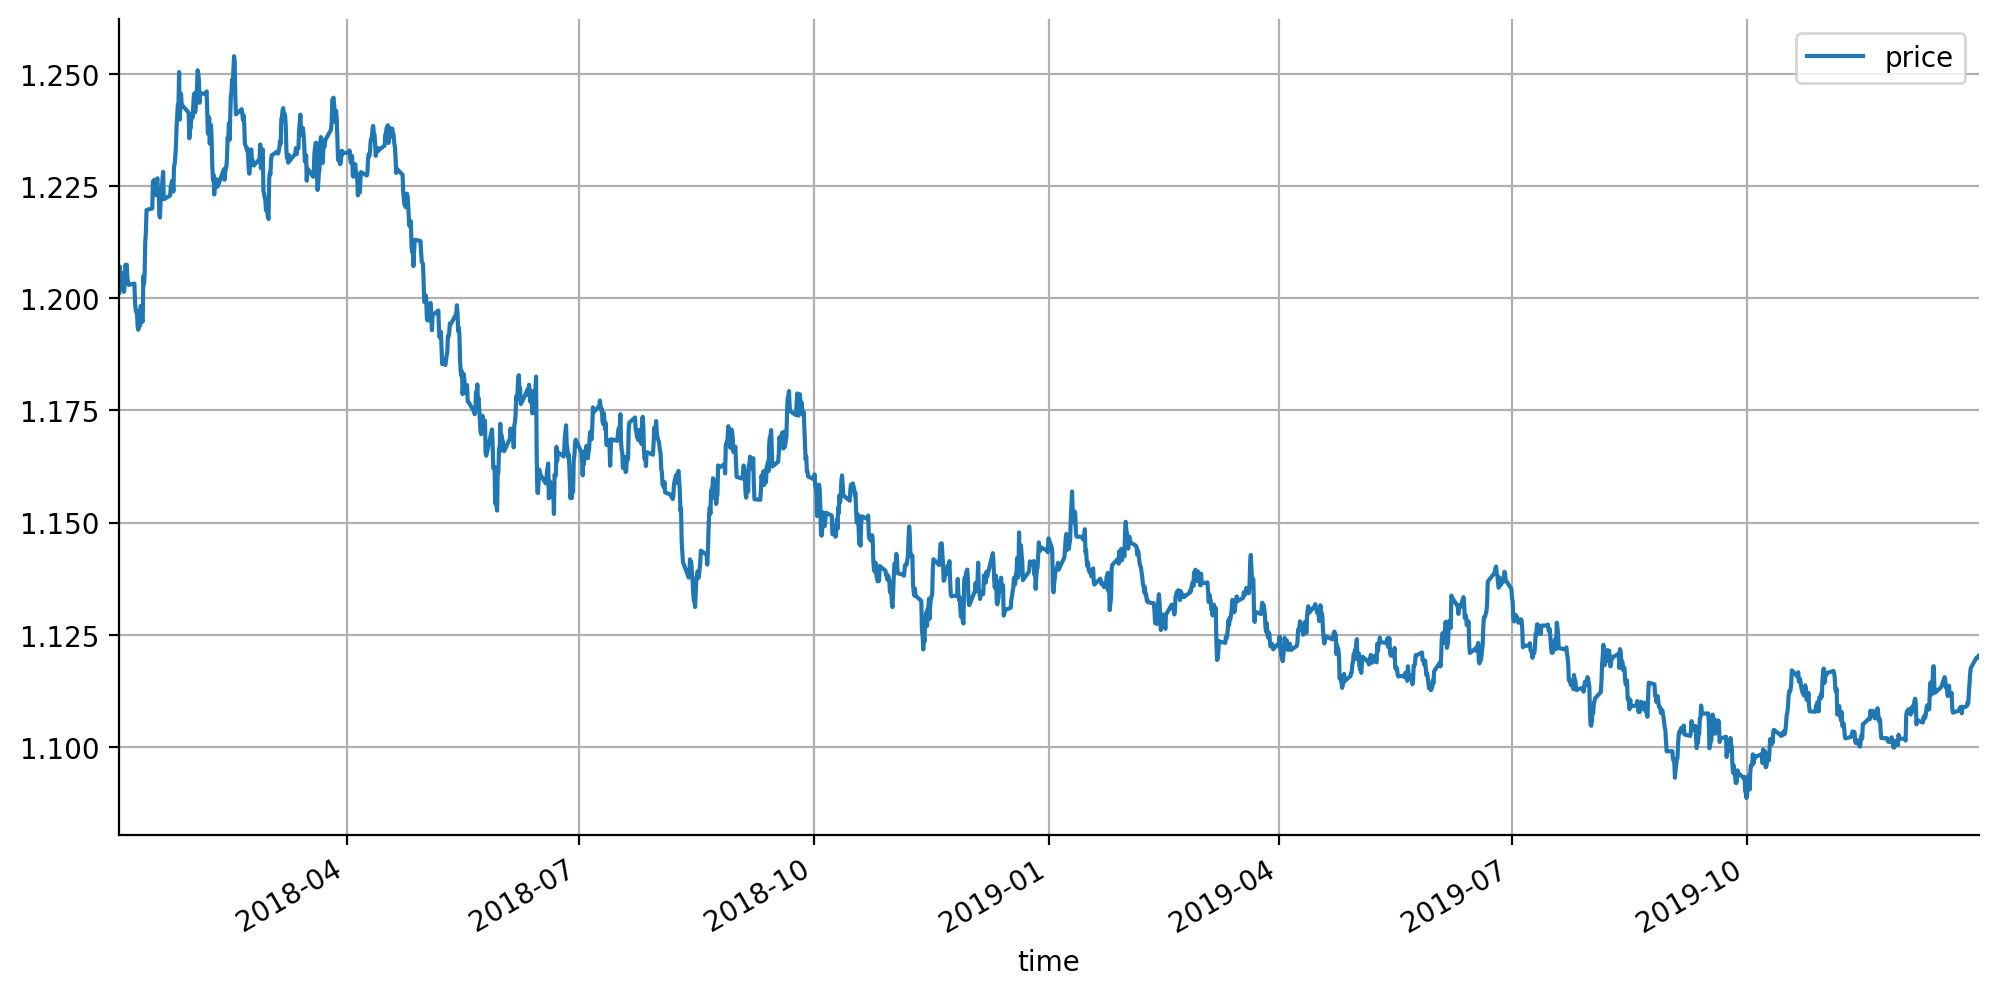

In [108]:
data.plot(figsize = (12, 6))
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.grid()
plt.show()

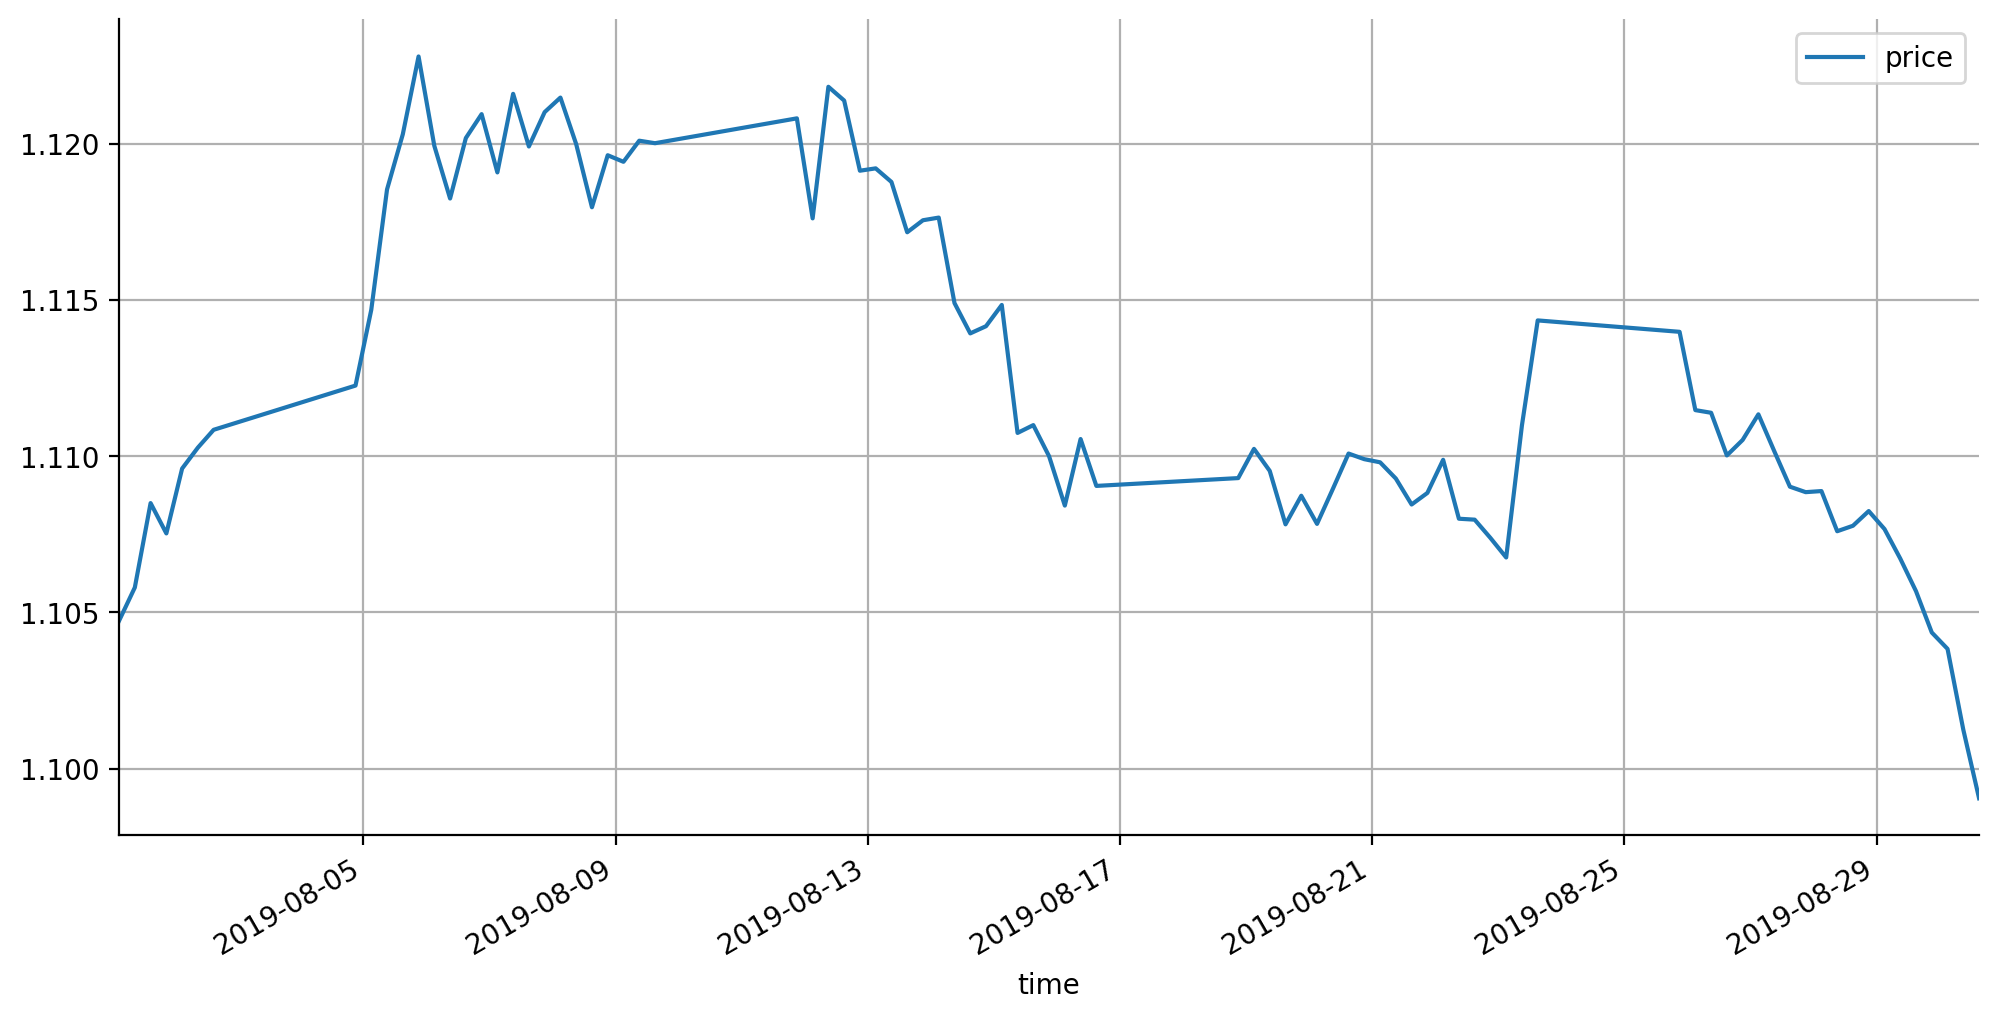

In [109]:
data.loc["2019-08"].plot(figsize = (12, 6))
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.grid()
plt.show()

In [110]:
data["returns"] = np.log(data.div(data.shift(1)))

In [111]:
data

,price,returns
time,,
2018-01-01 22:00:00+00:00,1.201205,NaN
2018-01-02 04:00:00+00:00,1.207055,0.004858
2018-01-02 10:00:00+00:00,1.204440,-0.002169
2018-01-02 16:00:00+00:00,1.205800,0.001129
2018-01-02 22:00:00+00:00,1.204690,-0.000921
...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092
2019-12-30 04:00:00+00:00,1.119940,0.000018
2019-12-30 10:00:00+00:00,1.120095,0.000138


## Defining a Mean-Reversion Strategy (Bollinger Bands) (Part 1)

__Mean Reversion__: Financial Instruments are from time to time overbought / oversold and revert back to mean prices. 

__Bollinger Bands__: Consists of a SMA (e.g. 30) and Upper and Lower Bands +- (2) Std Dev away from SMA.

In [112]:
SMA = 30
dev = 2

In [113]:
data["SMA"] = data["price"].rolling(SMA).mean()

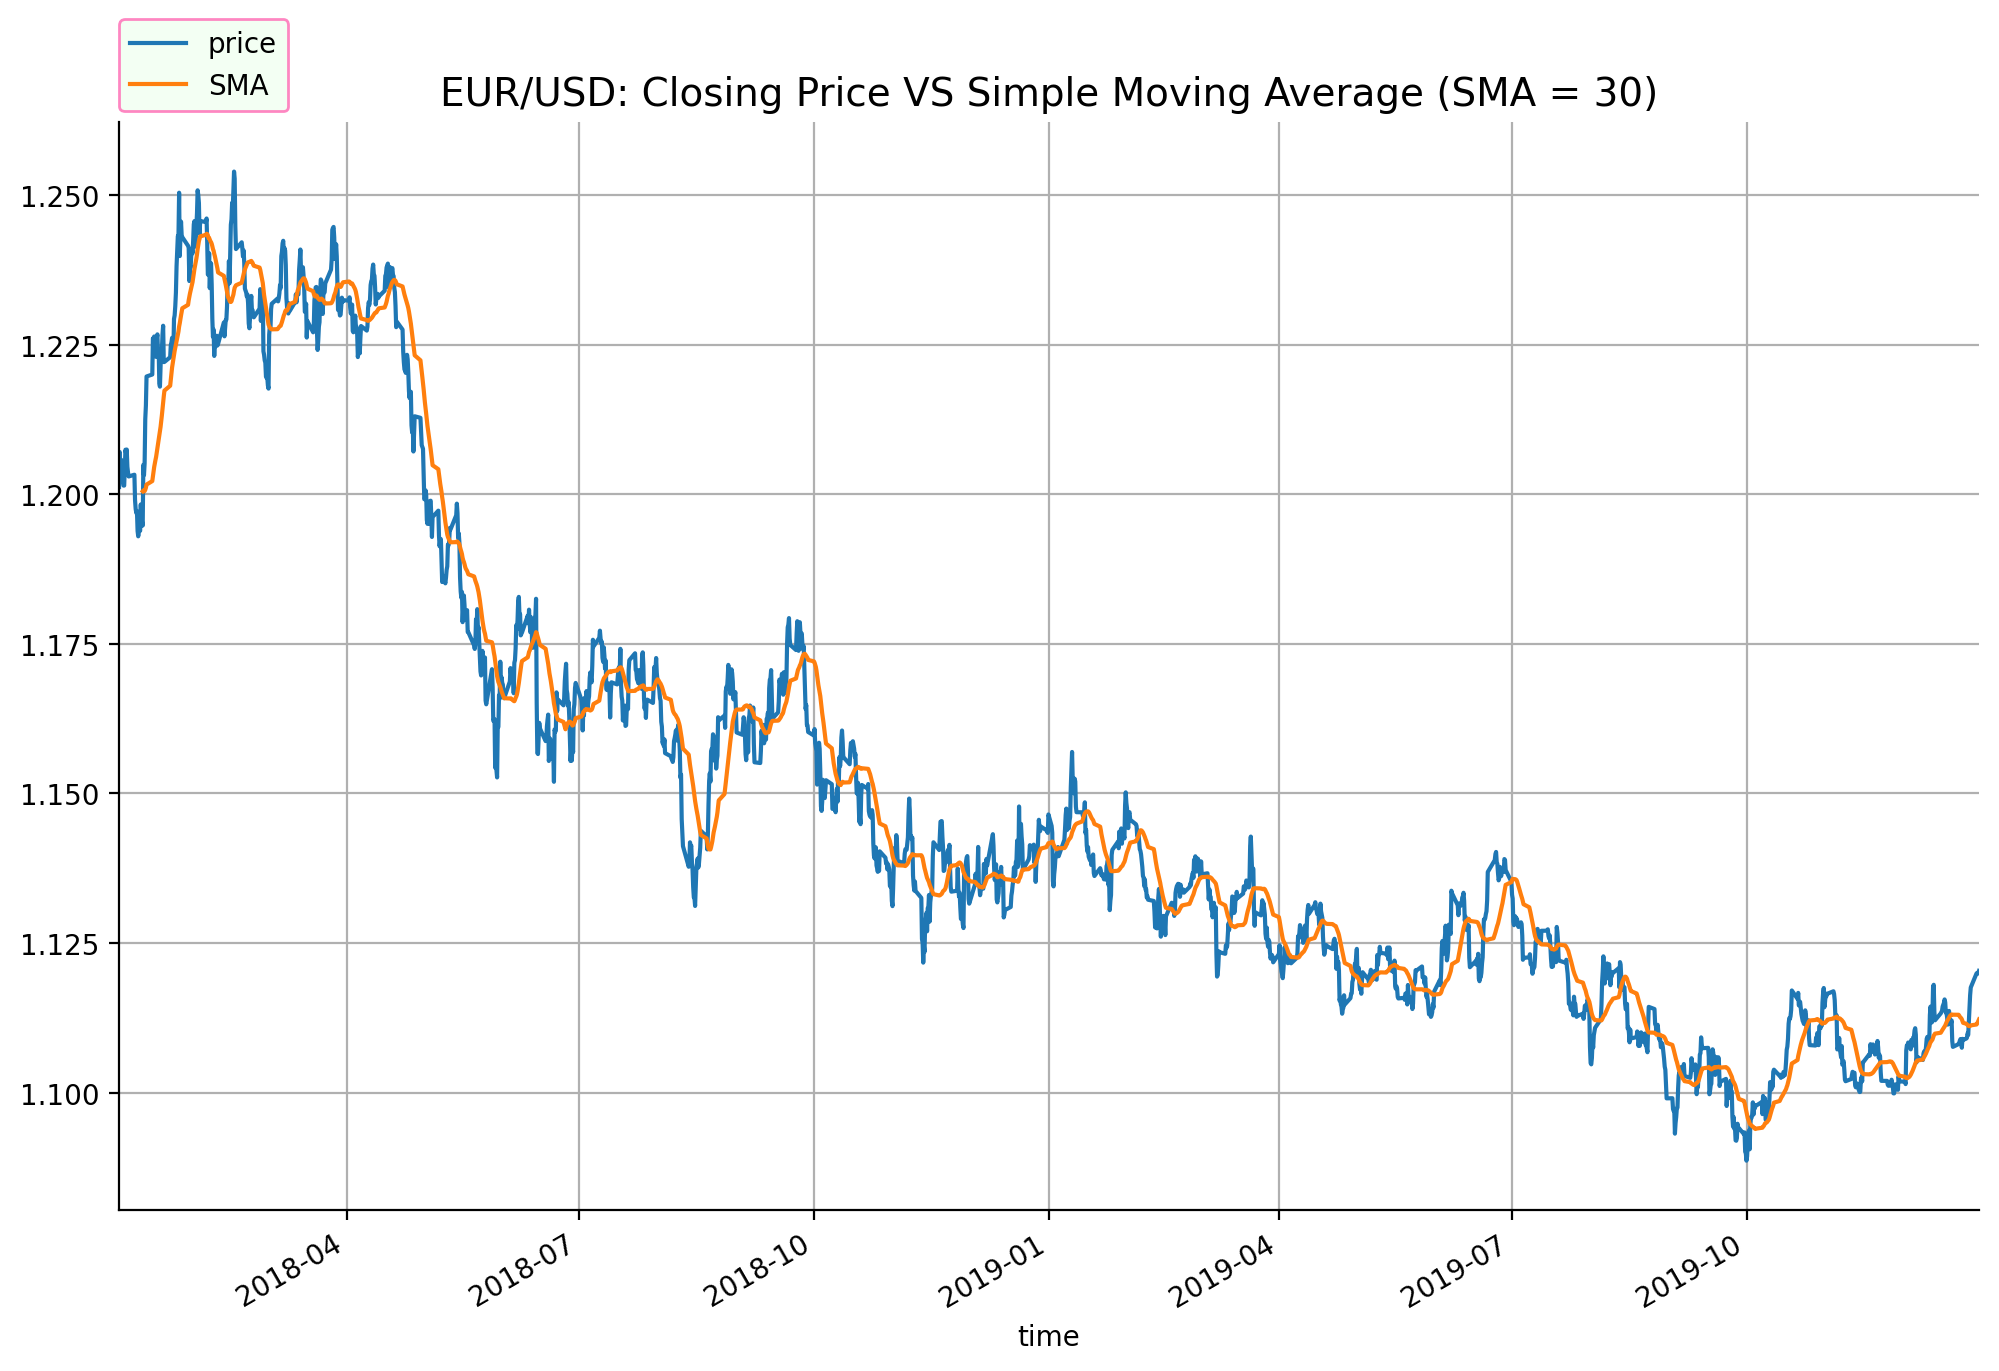

In [114]:
data[["price", "SMA"]].plot(figsize = (12, 8))
plt.title(f"EUR/USD: Closing Price VS Simple Moving Average (SMA = {SMA})" , fontsize = 14)
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
plt.grid()
plt.show()

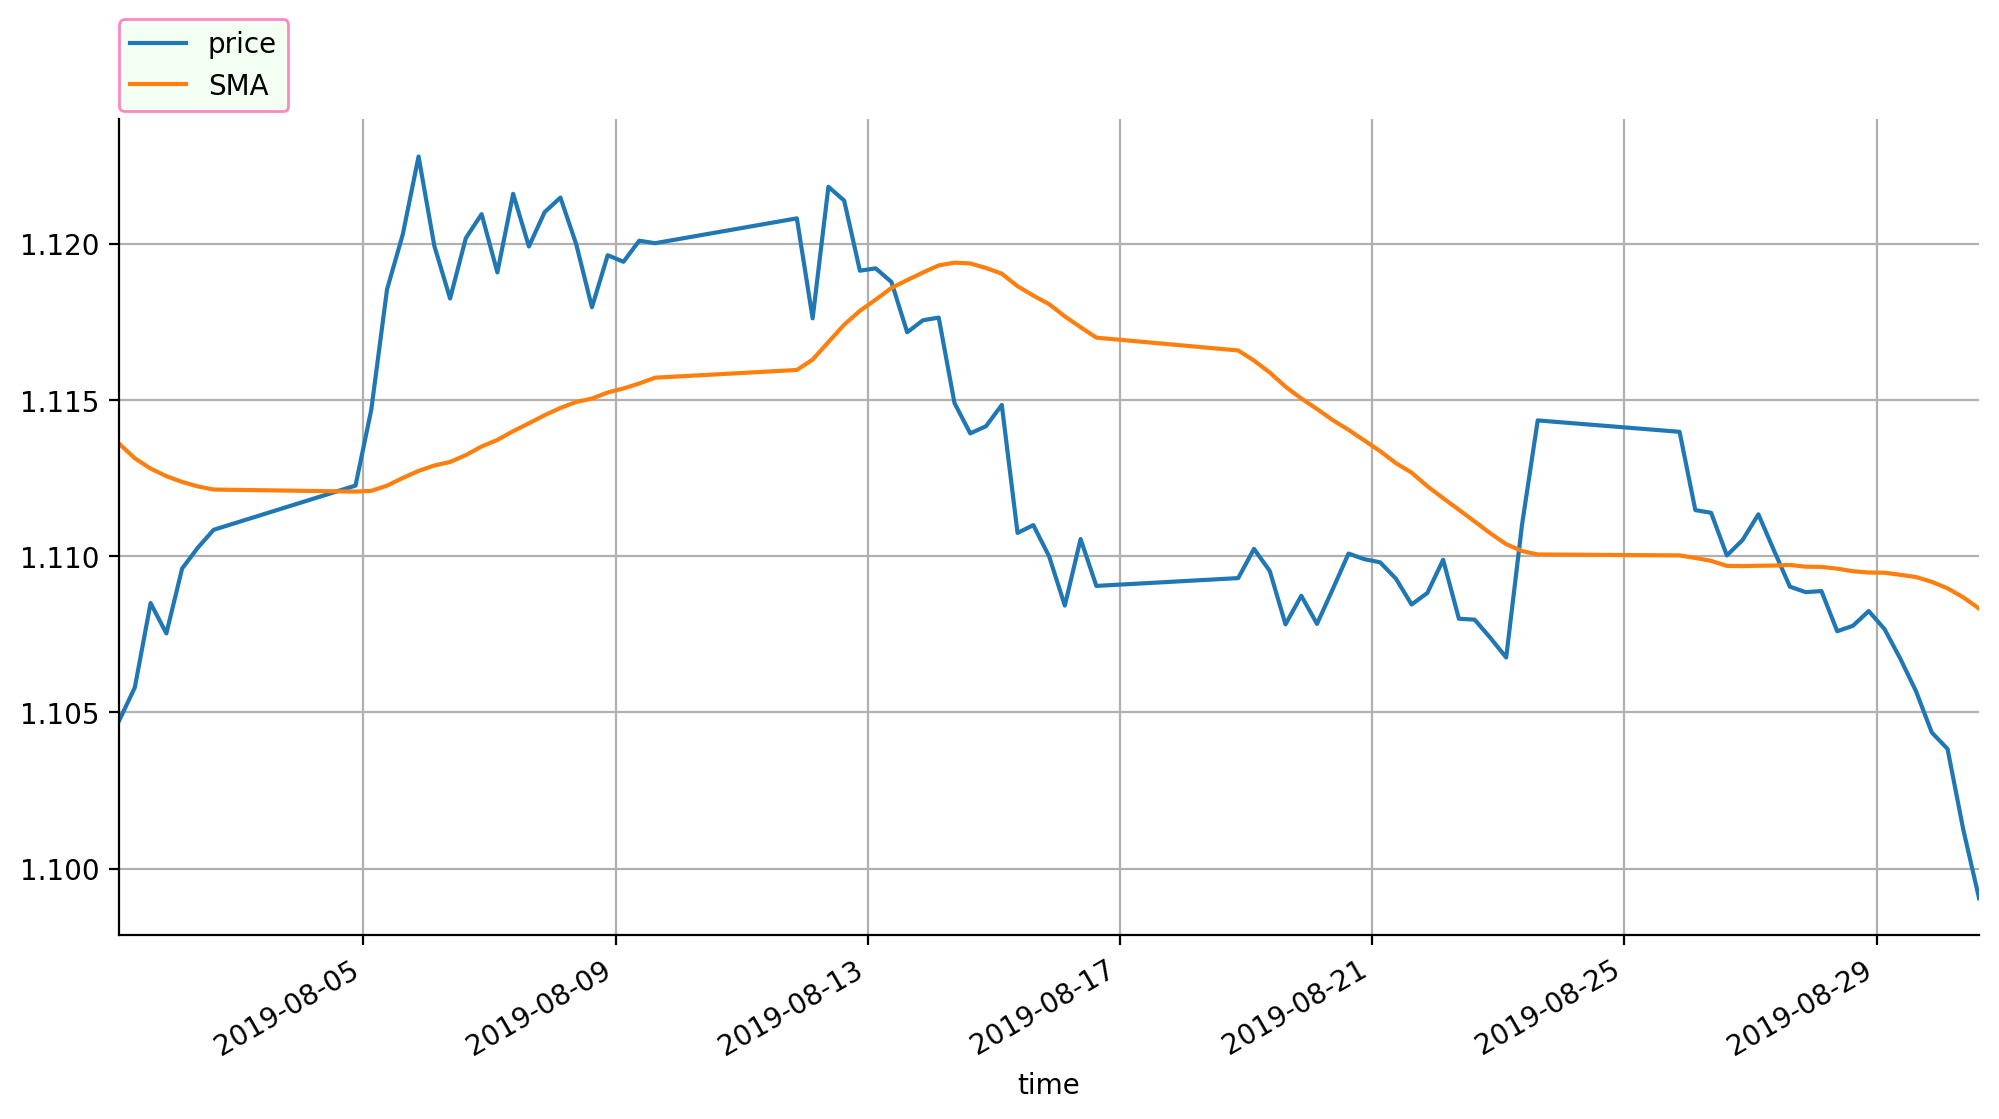

In [115]:
data.loc["2019-08", ["price", "SMA"]].plot(figsize = (12, 6))
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
plt.grid()
plt.show()

In [116]:
data["price"].rolling(SMA).std()

time
2018-01-01 22:00:00+00:00         NaN
2018-01-02 04:00:00+00:00         NaN
2018-01-02 10:00:00+00:00         NaN
2018-01-02 16:00:00+00:00         NaN
2018-01-02 22:00:00+00:00         NaN
                               ...   
2019-12-29 22:00:00+00:00    0.003088
2019-12-30 04:00:00+00:00    0.003400
2019-12-30 10:00:00+00:00    0.003729
2019-12-30 16:00:00+00:00    0.004008
2019-12-30 22:00:00+00:00    0.004288
Name: price, Length: 2070, dtype: float64

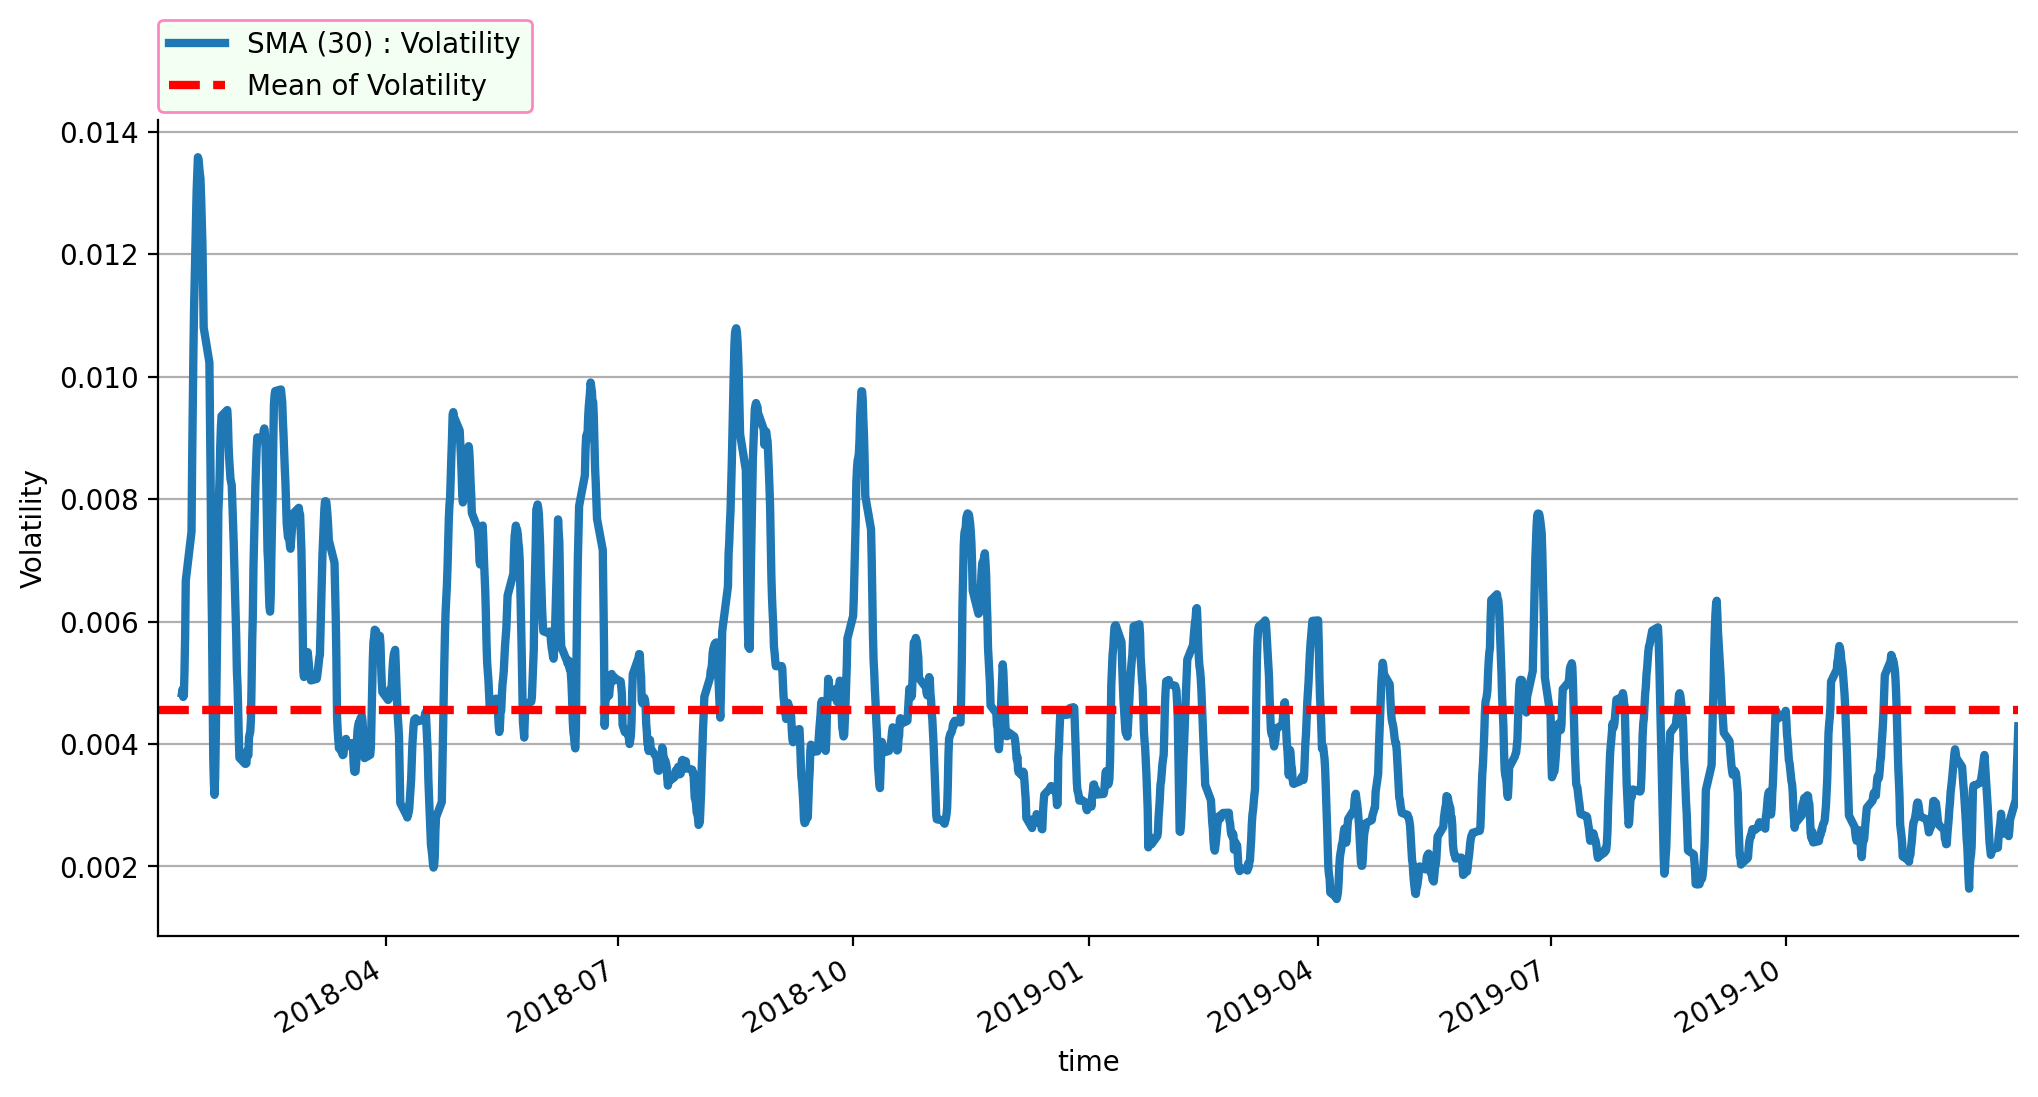

In [117]:
data["price"].rolling(SMA).std().plot(figsize = (12,6), label = f"SMA ({SMA}) : Volatility" , lw = 3)
plt.hlines(y = data["price"].rolling(SMA).std().mean(), xmin = data["price"].index[0] , xmax = data["price"].index[-1]  , ls = "--" , lw = 3 , color ="red" , label = "Mean of Volatility")
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.ylabel("Volatility")
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
plt.grid(axis ="y")
plt.show()

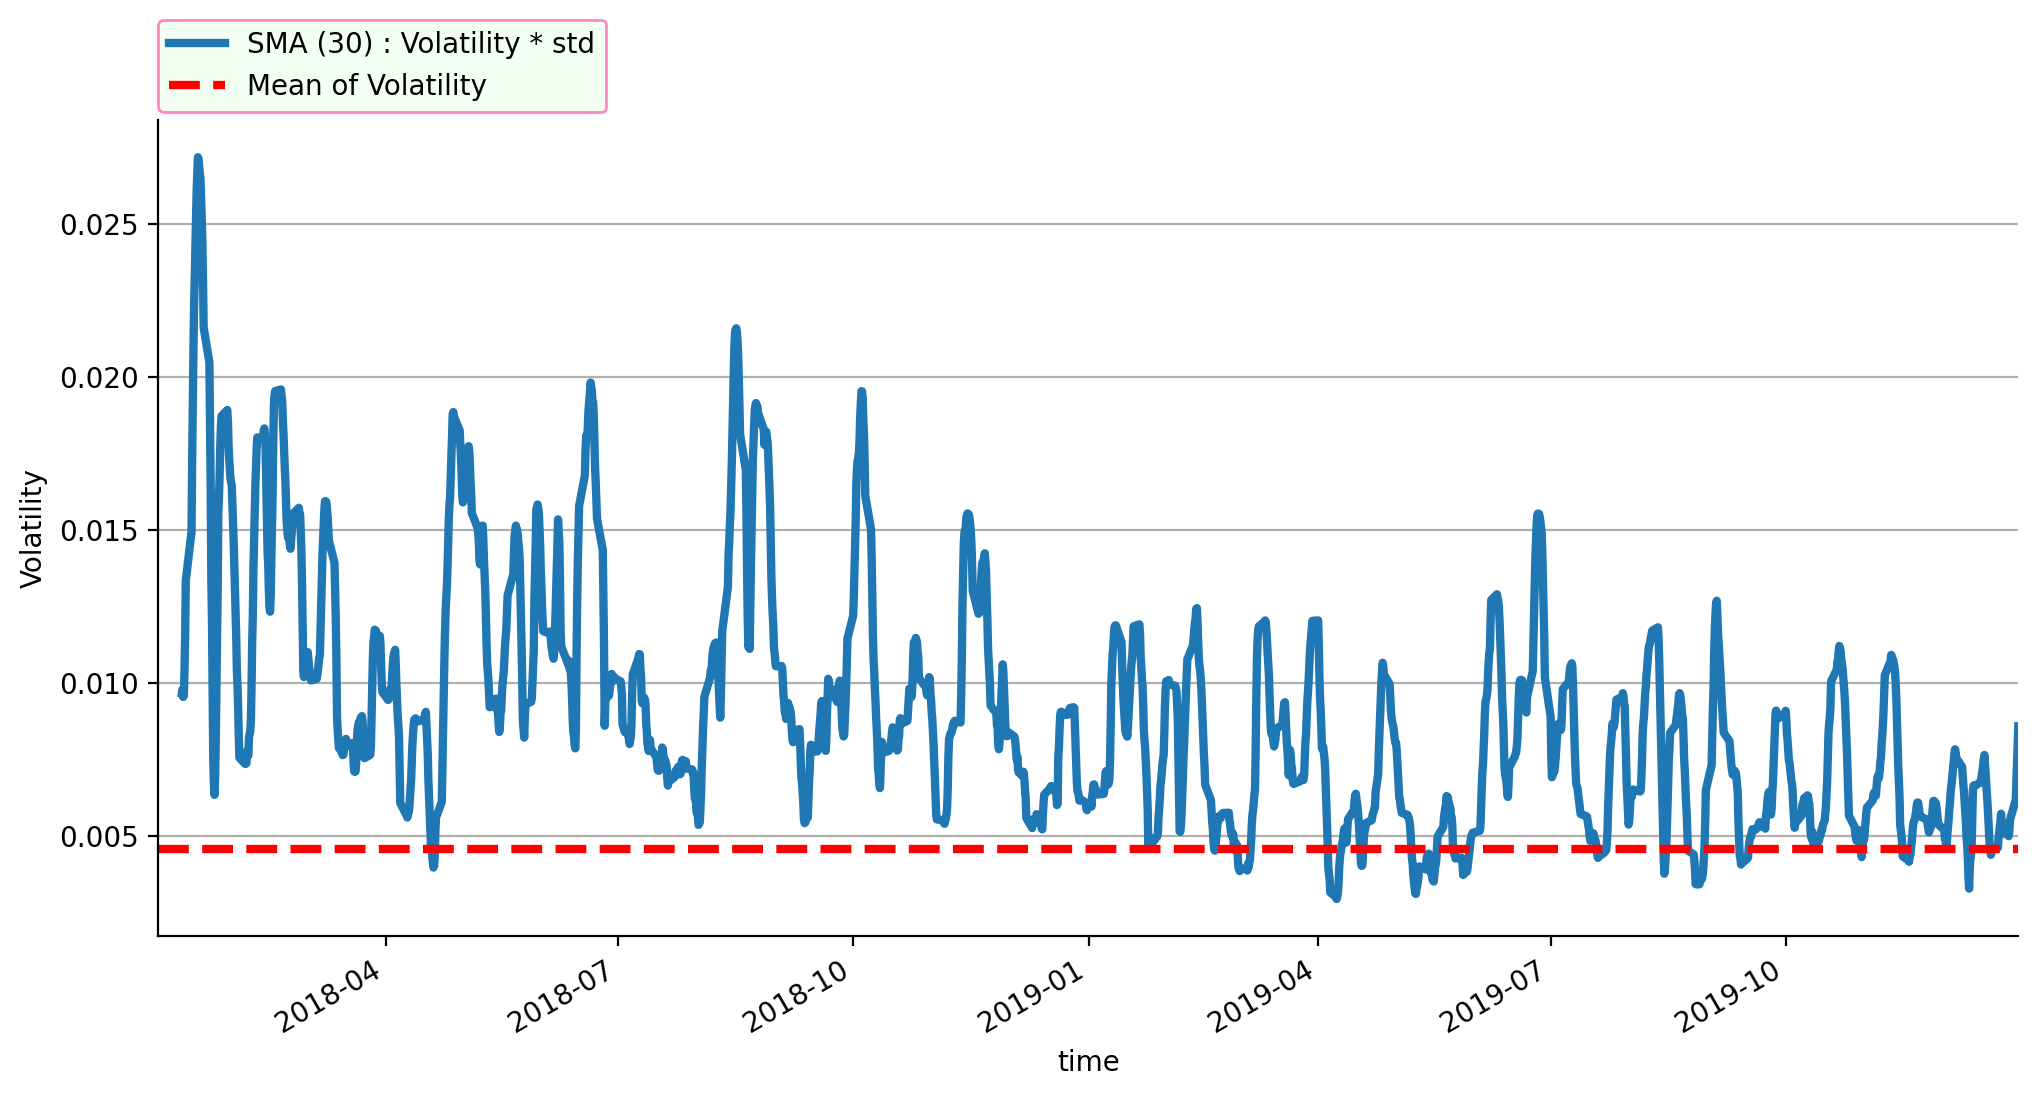

In [118]:
data["price"].rolling(SMA).std().mul(dev).plot(figsize = (12,6), label = f"SMA ({SMA}) : Volatility * std" , lw = 3)
plt.hlines(y = data["price"].rolling(SMA).std().mean(), xmin = data["price"].index[0] , xmax = data["price"].index[-1]  , ls = "--" , lw = 3 , color ="red" , label = "Mean of Volatility")
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.ylabel("Volatility")
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
plt.grid(axis ="y")
plt.show()

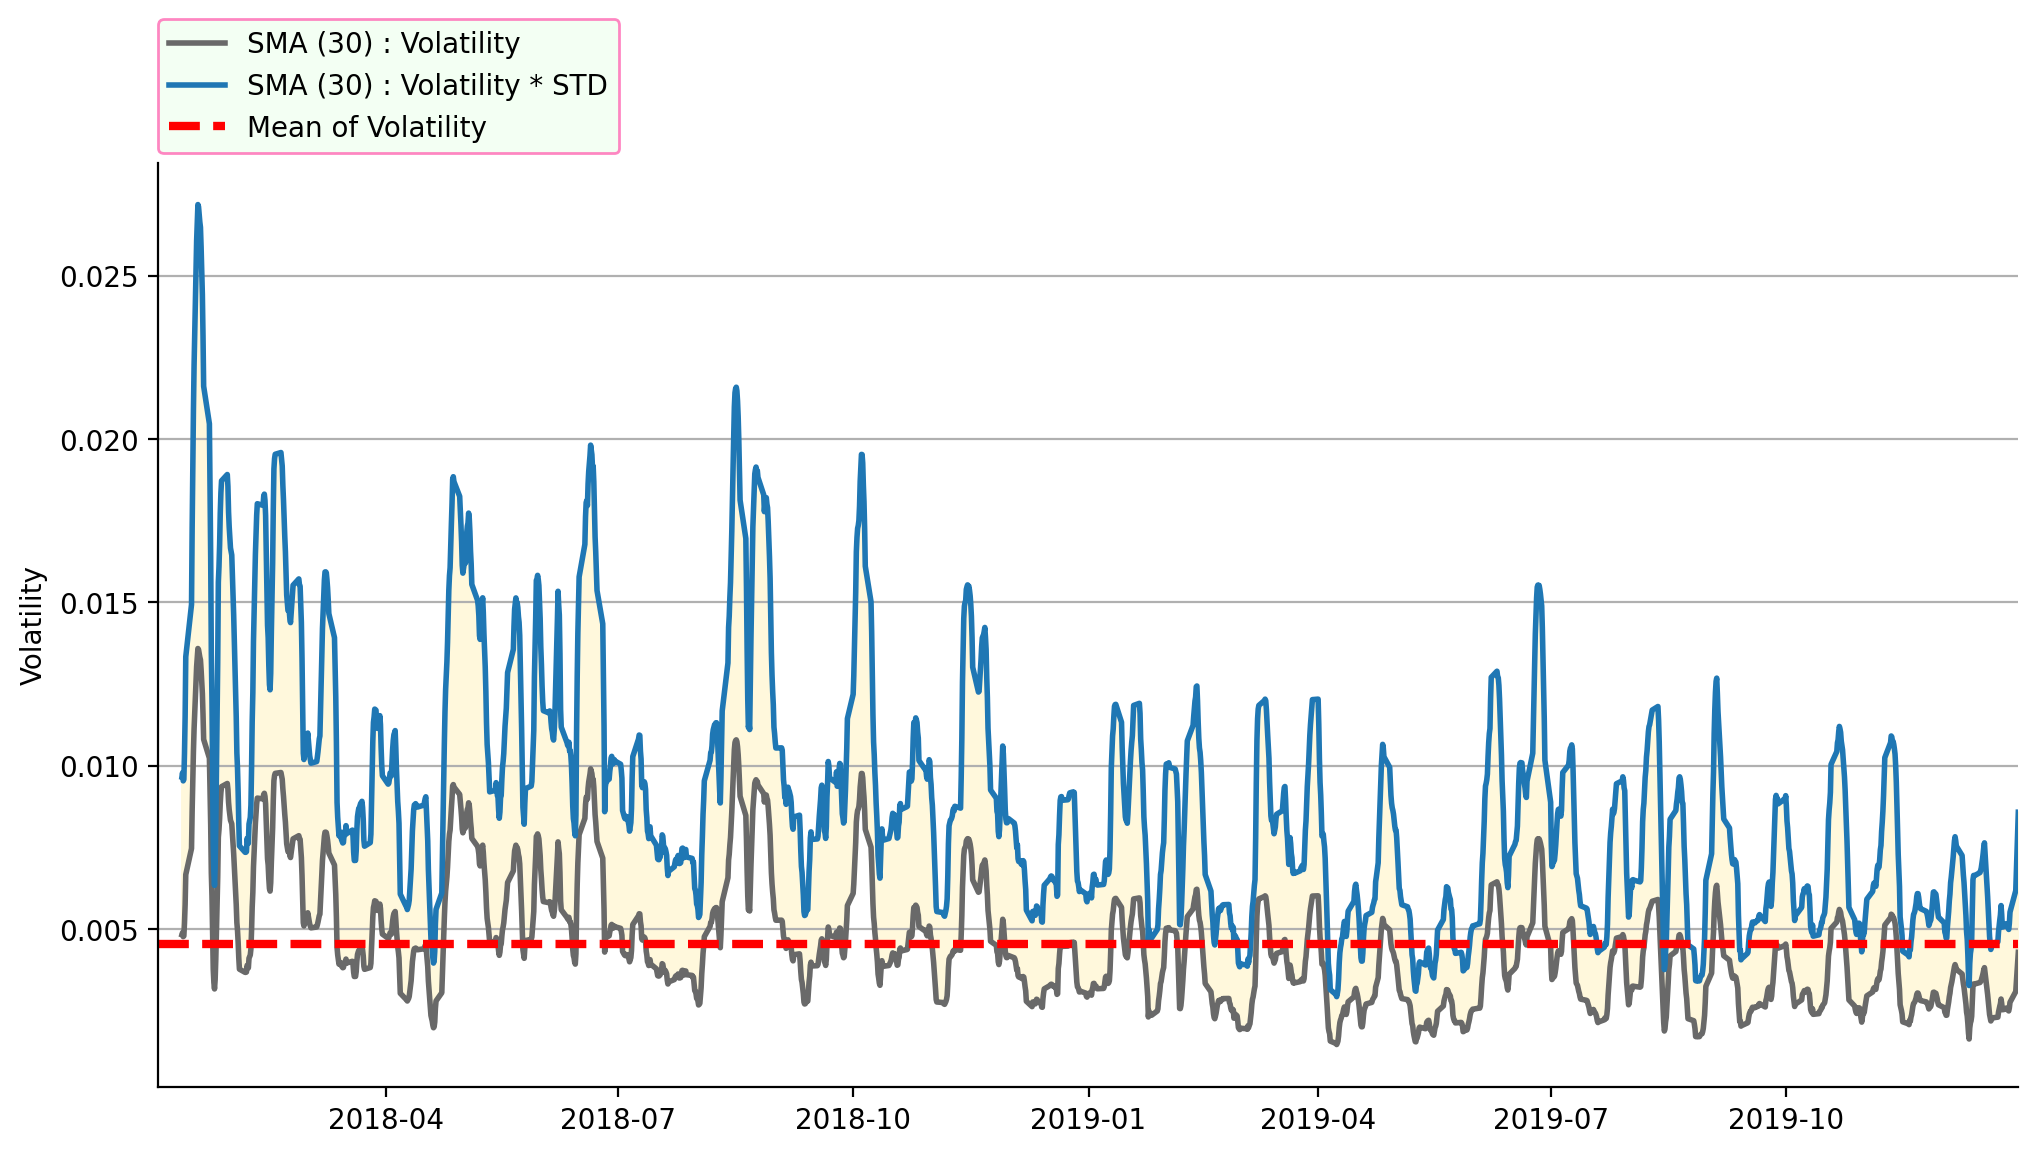

In [119]:
fig , ax = plt.subplots(figsize = (12,6))
ax.plot(data["price"].rolling(SMA).std(), label = f"SMA ({SMA}) : Volatility" , lw = 2 , color = "dimgray")
ax.plot(data["price"].rolling(SMA).std().mul(dev), label = f"SMA ({SMA}) : Volatility * STD" , lw = 2 )
ax.fill_between(y1 = data["price"].rolling(SMA).std() , y2 = data["price"].rolling(SMA).std().mul(dev) , x = data["price"].rolling(SMA).std().index , color = "cornsilk")
ax.hlines(y = data["price"].rolling(SMA).std().mean(), xmin = data["price"].index[0] , xmax = data["price"].index[-1]  , ls = "--" , lw = 3 , color ="red" , label = "Mean of Volatility")
fig.gca().spines[["top" , "right"]].set_visible(False)
ax.set_ylabel("Volatility")
ax.autoscale(enable = True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
ax.grid(axis ="y")
plt.show()

In [120]:
data["Lower_Band"] = data["SMA"] - data["price"].rolling(SMA).std() * dev # Lower Band -2 Std Dev
data["Upper_Band"] = data["SMA"] + data["price"].rolling(SMA).std() * dev # Upper Band +2 Std Dev
data = data.dropna()

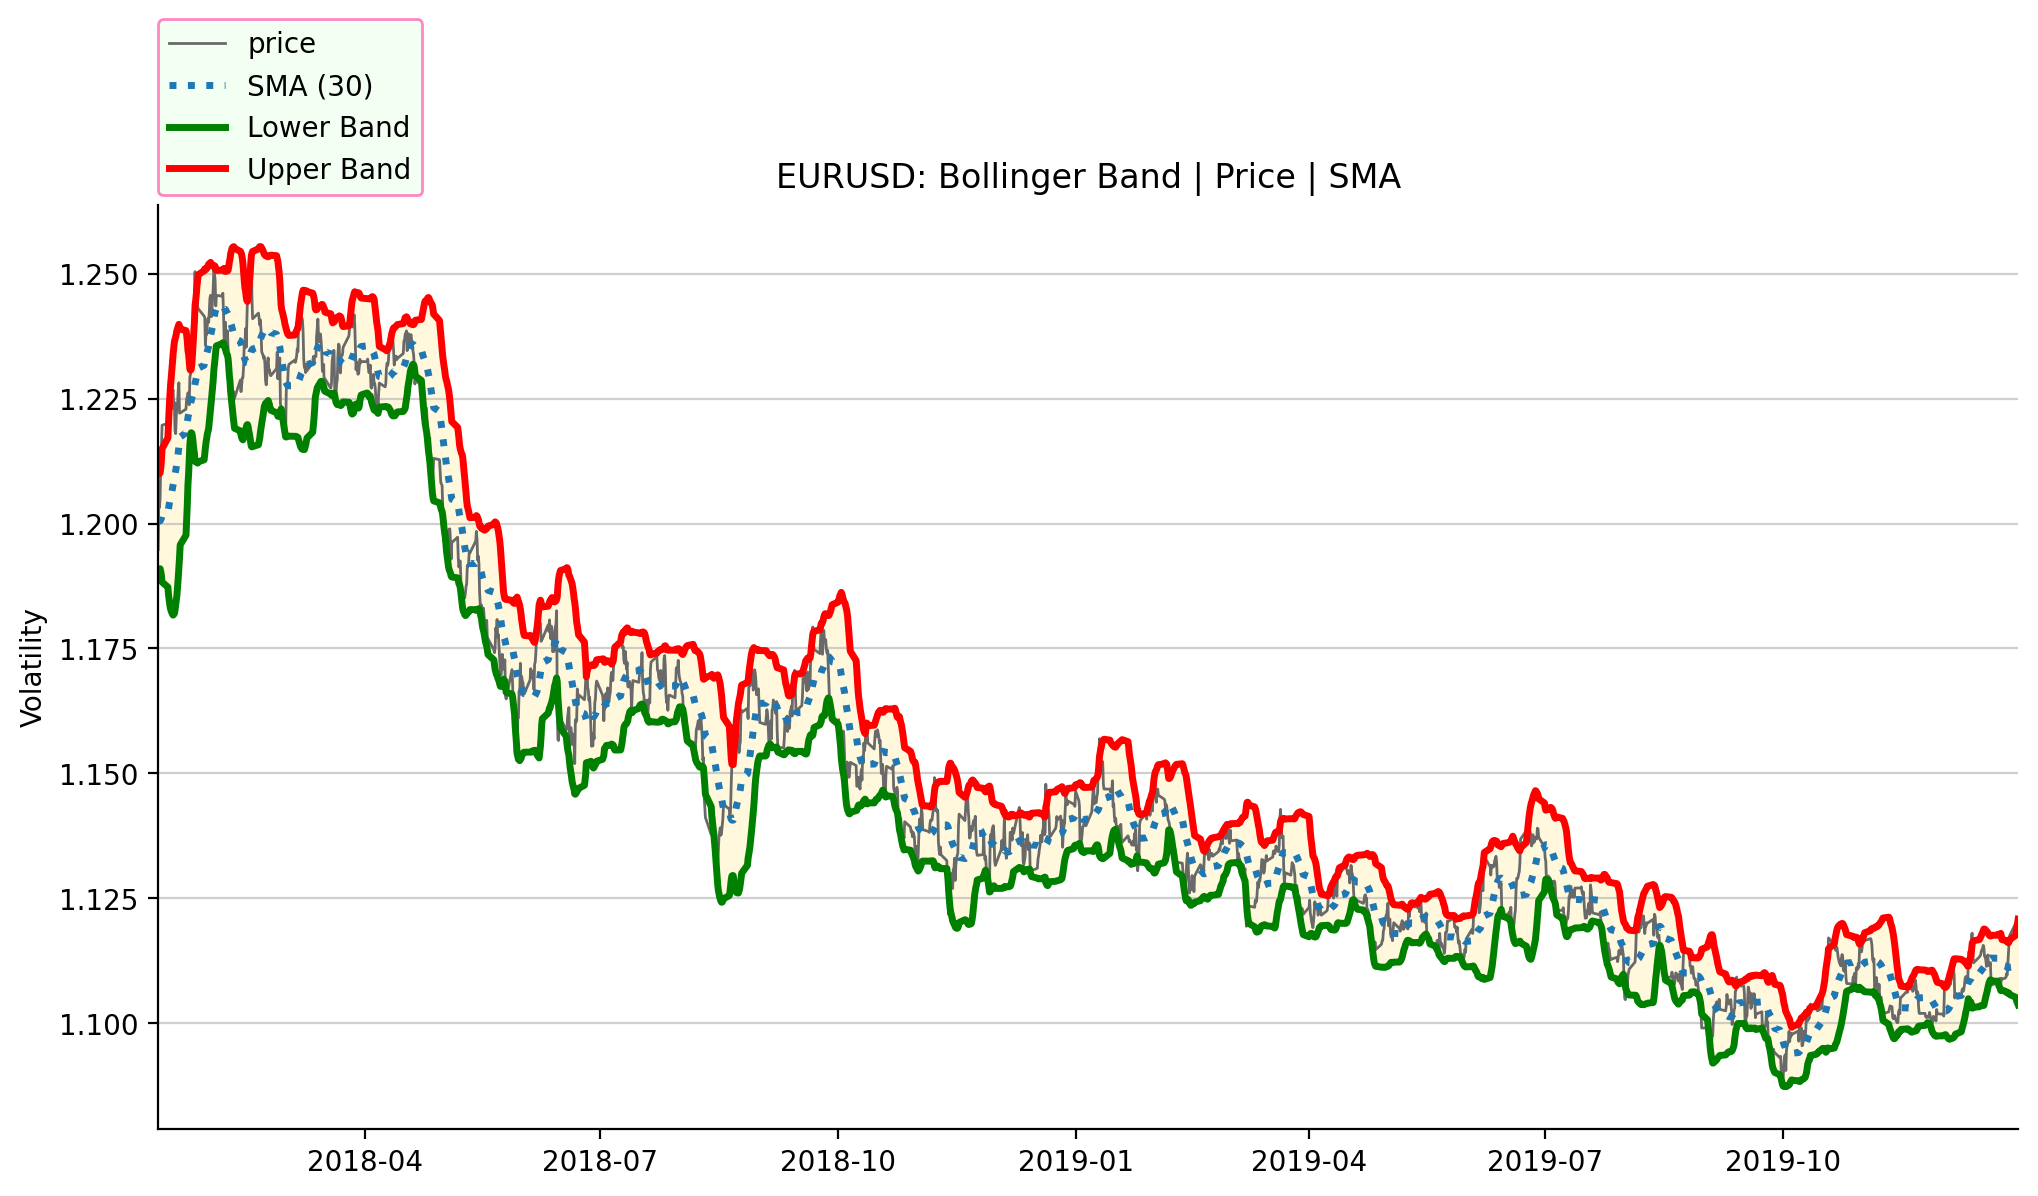

In [121]:
fig , ax = plt.subplots(figsize = (12,6))
ax.plot(data["price"], label = f"price" , lw = 1 , color = "dimgray")
ax.plot(data["SMA"], label = f"SMA ({SMA})" , lw = 2.5 , ls = ":" )
ax.plot(data["Lower_Band"], label = f"Lower Band" , lw = 2.5 , ls = "-", color ="green" )
ax.plot(data["Upper_Band"], label = f"Upper Band" , lw = 2.5 , ls = "-" , color = "red")
ax.fill_between(y1 = data["Lower_Band"] , y2 = data["Upper_Band"] , x = data["price"].index , color = "cornsilk")
ax.set_title("EURUSD: Bollinger Band | Price | SMA")
fig.gca().spines[["top" , "right"]].set_visible(False)
ax.set_ylabel("Volatility")
ax.autoscale(enable = True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
ax.grid(axis ="y" , alpha = .6)
plt.show()

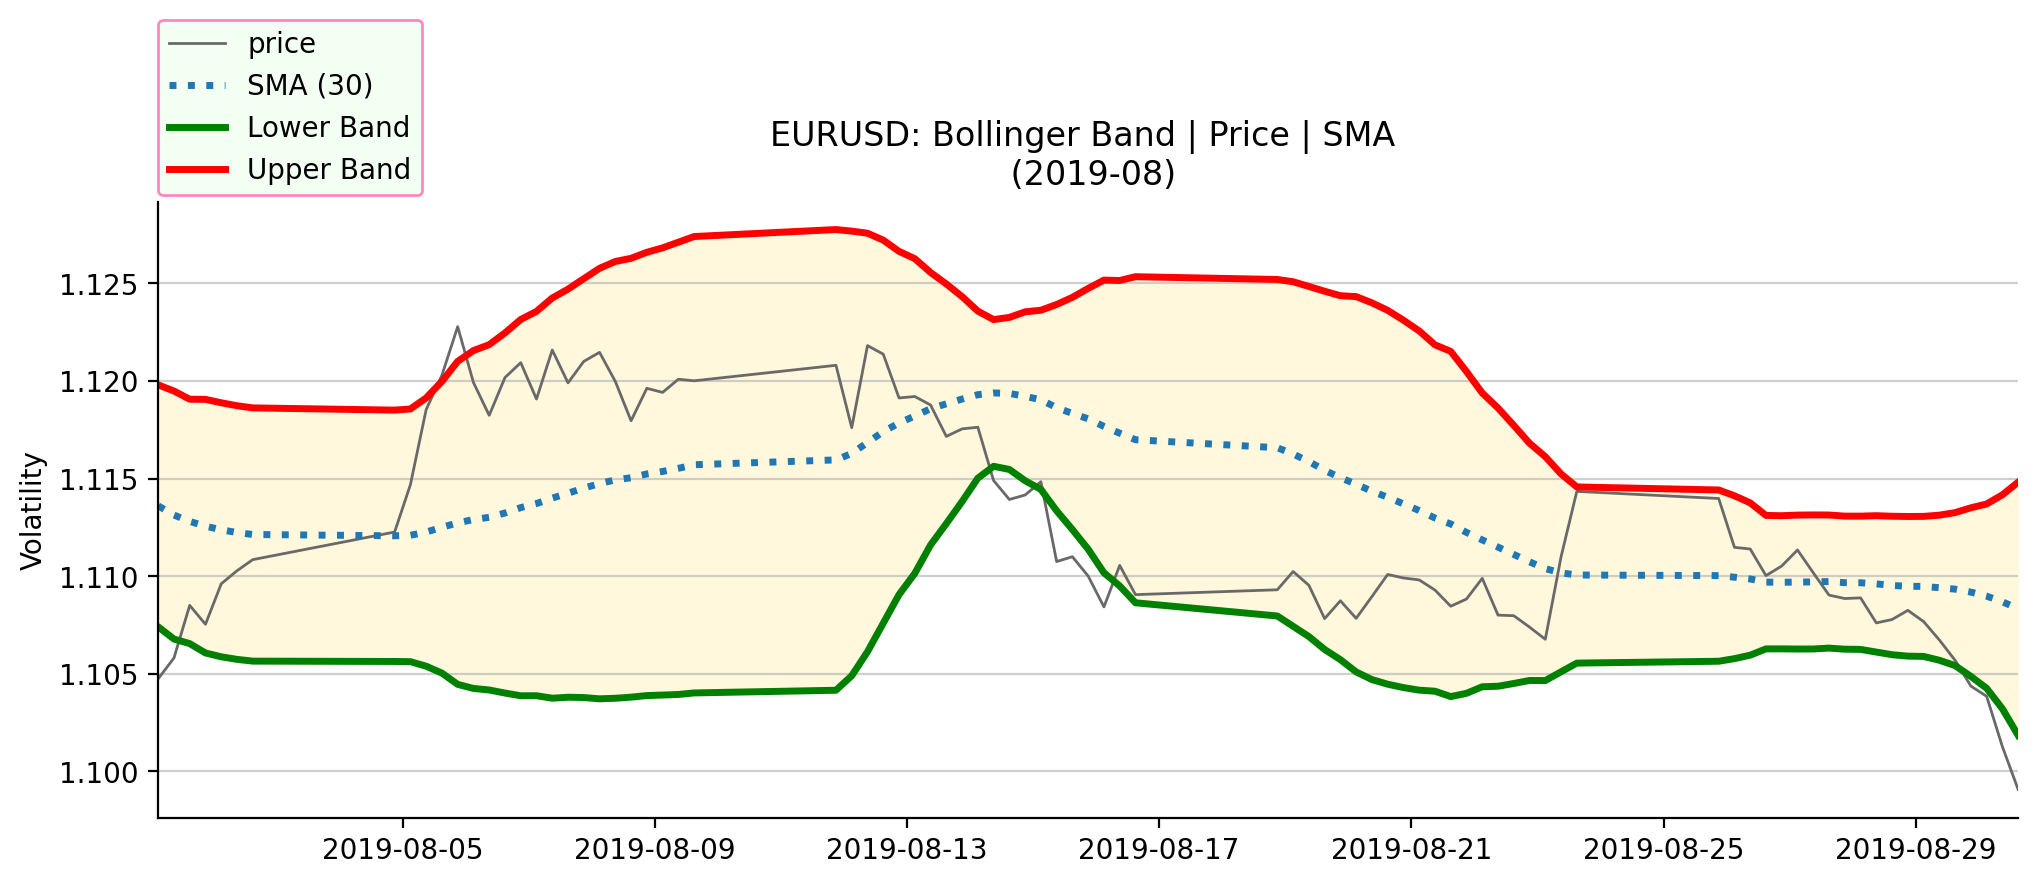

In [122]:
fig , ax = plt.subplots(figsize = (12,4))
ax.plot(data.loc["2019-08" ,"price"], label = f"price" , lw = 1 , color = "dimgray")
ax.plot(data.loc["2019-08" ,"SMA"], label = f"SMA ({SMA})" , lw = 2.5 , ls = ":" )
ax.plot(data.loc["2019-08" ,"Lower_Band"], label = f"Lower Band" , lw = 2.5 , ls = "-", color ="green" )
ax.plot(data.loc["2019-08" ,"Upper_Band"], label = f"Upper Band" , lw = 2.5 , ls = "-" , color = "red")
ax.fill_between(y1 = data.loc["2019-08" ,"Lower_Band"] , y2 = data.loc["2019-08" ,"Upper_Band"] , x = data.loc["2019-08" ,"price"].index , color = "cornsilk")
ax.set_title("EURUSD: Bollinger Band | Price | SMA \n (2019-08)")
fig.gca().spines[["top" , "right"]].set_visible(False)
ax.set_ylabel("Volatility")
ax.autoscale(enable = True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
ax.grid(axis ="y" , alpha = .6)
plt.show()

## Defining a Mean-Reversion Strategy (Bollinger Bands) (Part 2)

In [158]:
data

,price,returns,SMA,Lower_Band,Upper_Band,distance,position
time,,,,,,,
2018-01-11 04:00:00+00:00,1.194770,-0.000498,1.200504,1.190849,1.210160,-0.005734,NaN
2018-01-11 10:00:00+00:00,1.204915,0.008455,1.200628,1.190841,1.210415,0.004287,0.0
2018-01-11 16:00:00+00:00,1.203205,-0.001420,1.200500,1.190964,1.210035,0.002705,NaN
2018-01-11 22:00:00+00:00,1.205165,0.001628,1.200524,1.190943,1.210104,0.004641,NaN
2018-01-12 04:00:00+00:00,1.212530,0.006093,1.200748,1.190374,1.211122,0.011782,-1.0
...,...,...,...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092,1.111391,1.105215,1.117567,0.008529,-1.0
2019-12-30 04:00:00+00:00,1.119940,0.000018,1.111553,1.104754,1.118352,0.008387,-1.0
2019-12-30 10:00:00+00:00,1.120095,0.000138,1.111777,1.104318,1.119235,0.008318,-1.0


In [159]:
data["distance"] = data["price"] - data["SMA"] # helper Column

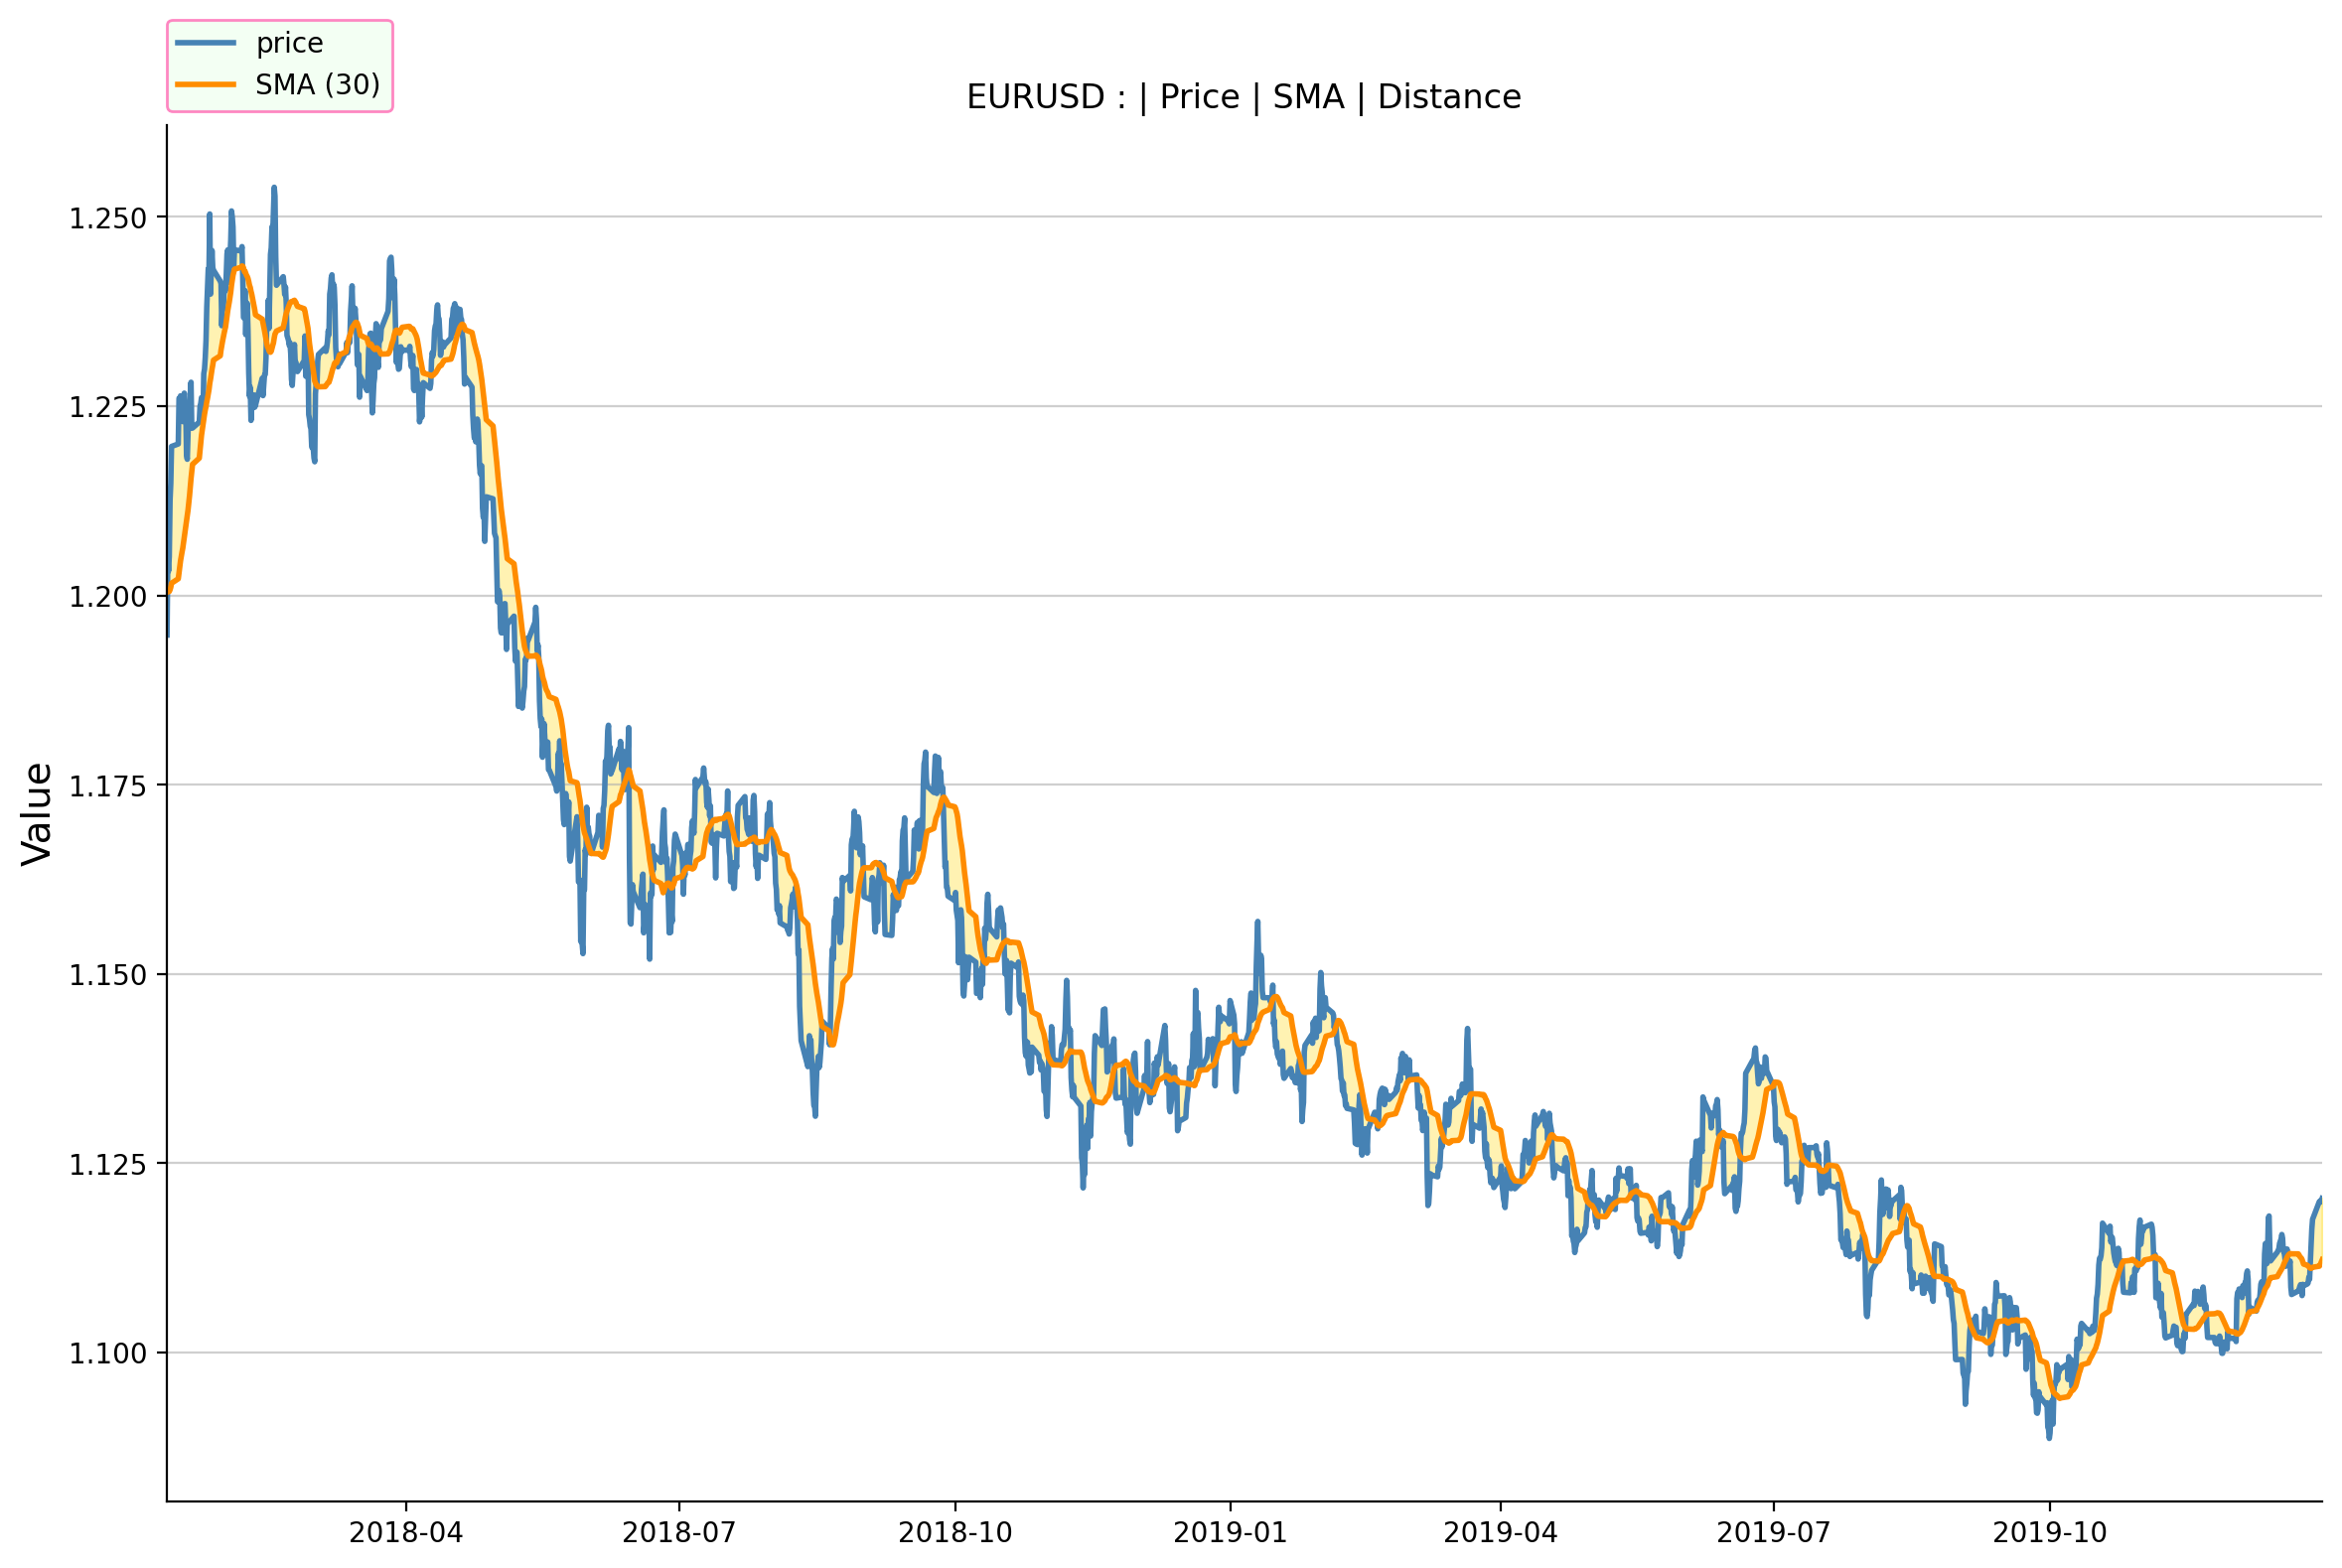

In [160]:
fig , ax = plt.subplots(figsize = (14,9))
ax.plot(data["price"], label = f"price" , lw = 2 , color = "steelblue")
ax.plot(data["SMA"], label = f"SMA ({SMA})" , lw = 2 , color = "darkorange" )
#ax.plot(data["distance"] , label = f"distance" , lw = 2.5 , ls = "-" , color ="green")
ax.fill_between(y1 = data["price"] , y2 = data["SMA"] , x = data["price"].index , color = "gold" , alpha = .3)
ax.set_title("EURUSD : | Price | SMA | Distance")
fig.gca().spines[["top" , "right"]].set_visible(False)
ax.set_ylabel("Value" , fontsize = 14)
ax.autoscale(enable = True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
ax.grid(axis ="y" , alpha = .6)
plt.show()

We already defined:
$$\text{distance}_{t} = \text{Price}_{t} - \text{SMA}_{t} $$

We cross the $\text{SMA}$'s line at the time t if and only if:

\begin{align}
\text{We cross the $\text{SMA}$'s line at the time } &\Longleftrightarrow \\
                                                     &\Longleftrightarrow
                                                     \text{distance}_{t} <0 \quad\&\quad\text{distance}_{t+1} >0 \\
                                                     &\Longleftrightarrow
                                                     \text{distance}_{t} \times \text{distance}_{t+1} < 0
\end{align}

In [170]:
data["position"] = np.where(data.price < data.Lower_Band , 1 , np.nan) # 1. oversold -> go long
data["position"] = np.where(data.price > data.Upper_Band , -1 , data["position"]) # 2. overbought -> go short
data["position"] = np.where(data.distance * data.distance.shift(1) < 0 , 0 , data["position"]) # 3. crossing SMA ("Middle Band") -> go neutral

In [175]:
data["position"] = data.position.ffill().fillna(0) # where 1-3 isn´t applicable -> hold previous position

In [176]:
data.position.value_counts(dropna=False)

 0.0    919
 1.0    596
-1.0    526
Name: position, dtype: int64

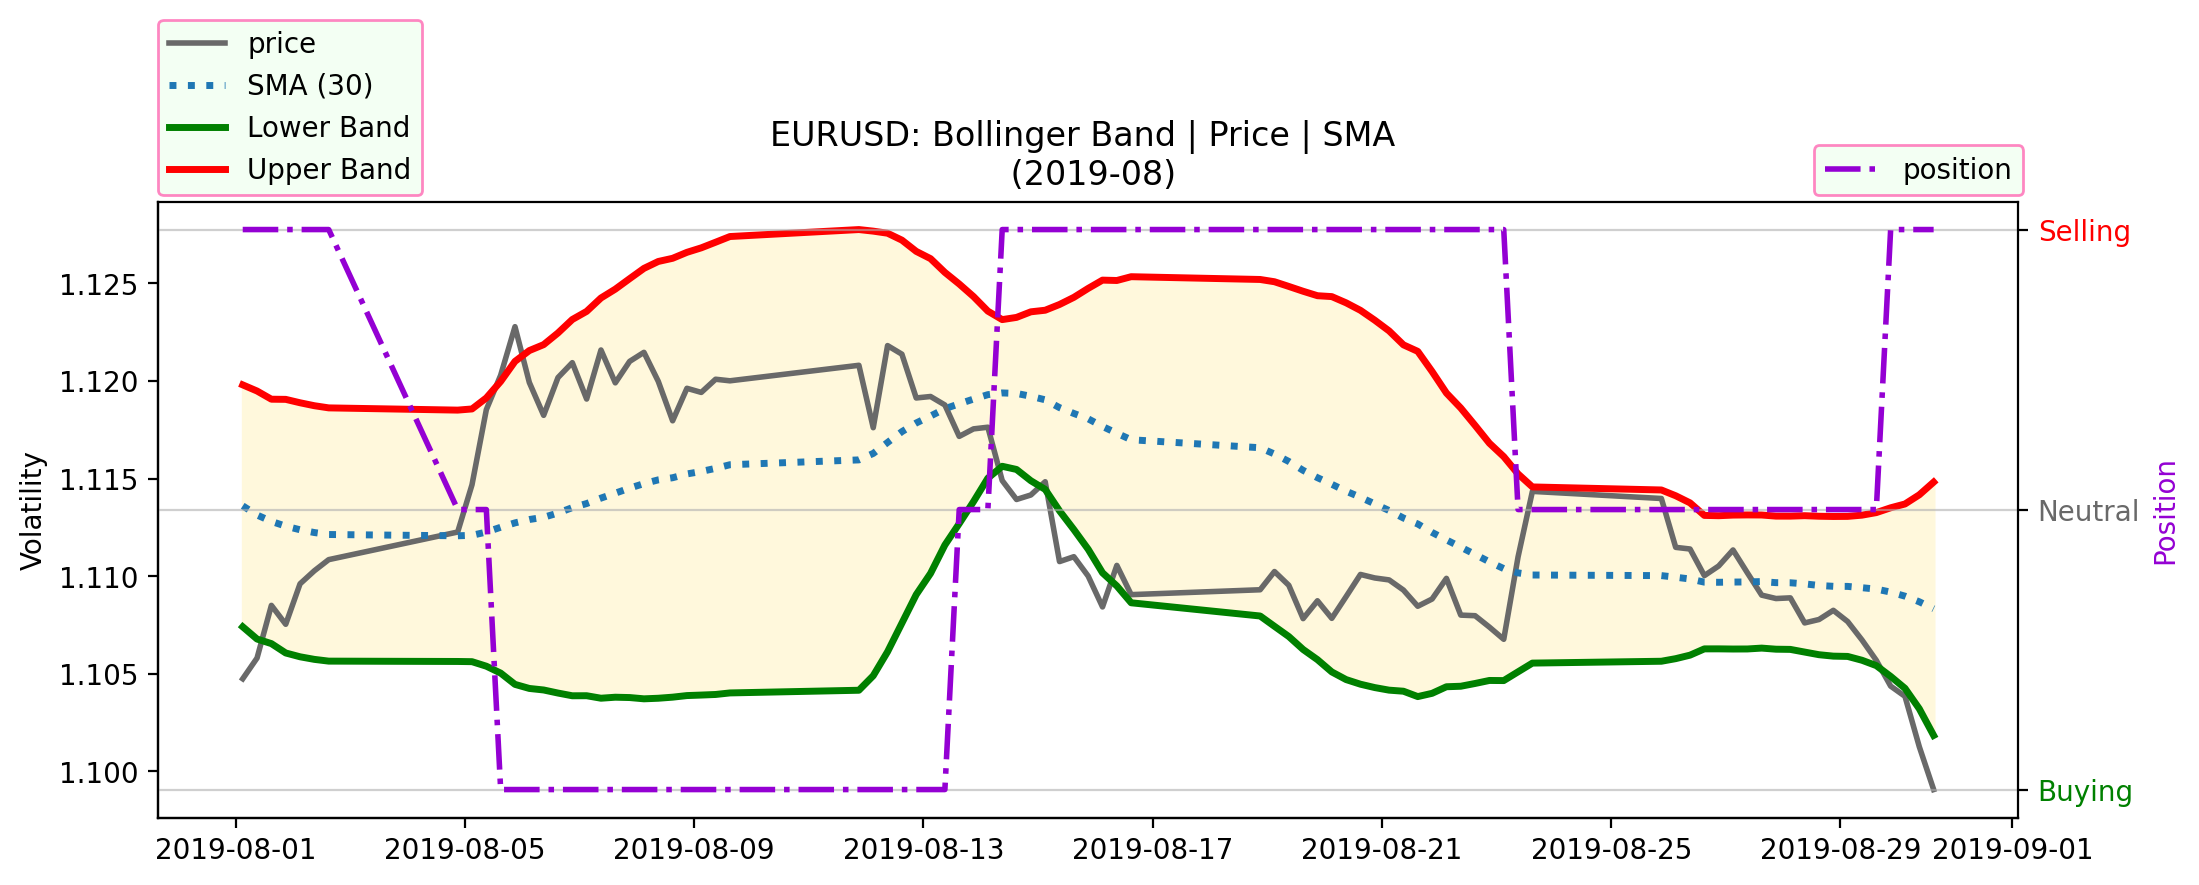

In [192]:
fig , ax = plt.subplots(figsize = (12,4))
ax.plot(data.loc["2019-08" , "price"] , label = f"price" , lw = 2 , color = "dimgray")
ax.plot(data.loc["2019-08" , "SMA"] , label = f"SMA ({SMA})" , lw = 2.5 , ls = ":" )
ax.plot(data.loc["2019-08" , "Lower_Band"] , label = f"Lower Band" , lw = 2.5 , ls = "-", color ="green" )
ax.plot(data.loc["2019-08" , "Upper_Band"] , label = f"Upper Band" , lw = 2.5 , ls = "-" , color = "red")
ax.fill_between(y1 = data.loc["2019-08" , "Lower_Band"] , y2 = data.loc["2019-08" ,"Upper_Band"] , x = data.loc["2019-08" ,"price"].index , color = "cornsilk")
ax.set_title("EURUSD: Bollinger Band | Price | SMA \n (2019-08)")
fig.gca().spines[["top" , "right"]].set_visible(False)
ax.set_ylabel("Volatility")
ax.autoscale(enable = True , axis ="x" , tight = True)
ax.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")


ax2 = ax.twinx()
ax2.plot(data.loc["2019-08" , "position"] , label = f"position" , lw = 2 , ls = "-." , color = "darkviolet")
ax2.set_ylabel("Position" , color = "darkviolet")
ax2.set_yticks(ticks = [-1 , 0 , +1])
ax2.set_yticklabels(labels = ["Buying" , "Neutral" , "Selling"])
ax2.legend(loc = (.89,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
ax2.grid(axis ="y" , alpha = .6)
for ticker in ax2.get_yticklabels():
    if ticker.get_text() == "Selling":
        ticker.set_color("red")
    elif ticker.get_text() == "Neutral":
        ticker.set_color("dimgray")
    else:
        ticker.set_color("green")


plt.show()

In [193]:
data

,price,returns,SMA,Lower_Band,Upper_Band,distance,position
time,,,,,,,
2018-01-11 04:00:00+00:00,1.194770,-0.000498,1.200504,1.190849,1.210160,-0.005734,0.0
2018-01-11 10:00:00+00:00,1.204915,0.008455,1.200628,1.190841,1.210415,0.004287,0.0
2018-01-11 16:00:00+00:00,1.203205,-0.001420,1.200500,1.190964,1.210035,0.002705,0.0
2018-01-11 22:00:00+00:00,1.205165,0.001628,1.200524,1.190943,1.210104,0.004641,0.0
2018-01-12 04:00:00+00:00,1.212530,0.006093,1.200748,1.190374,1.211122,0.011782,-1.0
...,...,...,...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092,1.111391,1.105215,1.117567,0.008529,-1.0
2019-12-30 04:00:00+00:00,1.119940,0.000018,1.111553,1.104754,1.118352,0.008387,-1.0
2019-12-30 10:00:00+00:00,1.120095,0.000138,1.111777,1.104318,1.119235,0.008318,-1.0


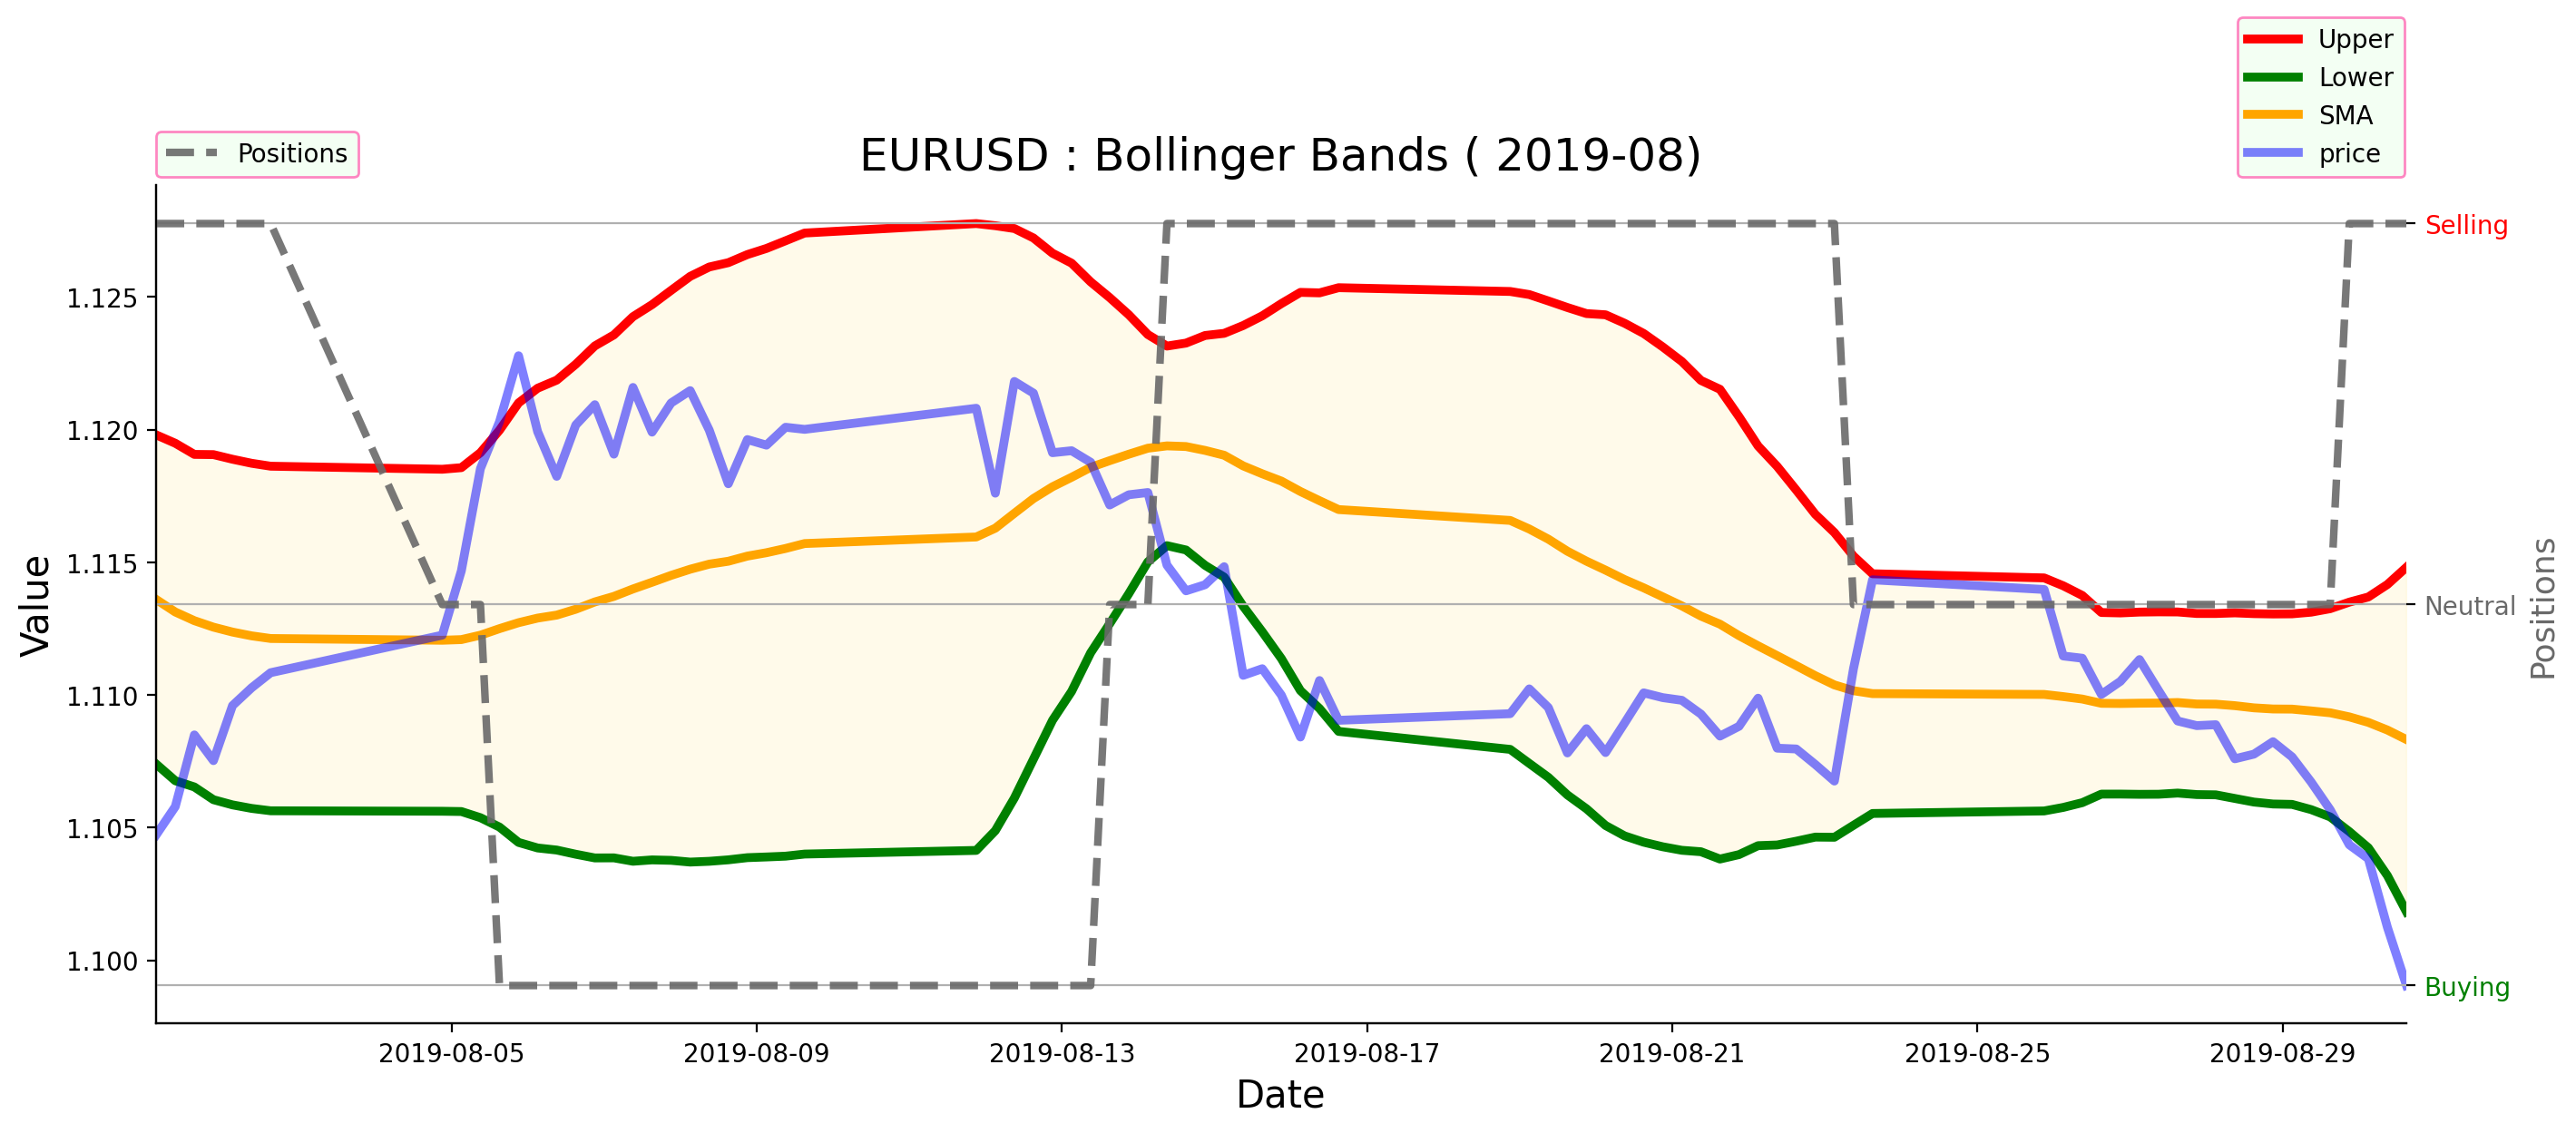

In [196]:
fig , ax = plt.subplots(figsize = (16,6))

#ax.plot(data.drop(columns = ["returns", "distance", "position"]).loc["2019-08"])
ax.plot(data.loc["2019-08" , "Upper_Band"] , lw = 3.5 , color = "red" , label = "Upper")
ax.plot(data.loc["2019-08" , "Lower_Band"] , lw = 3.5 , color = "green" , label = "Lower")
ax.plot(data.loc["2019-08" , "SMA"] , lw = 3.5 , color = "orange" , label = "SMA")
ax.plot(data.loc["2019-08" , "price"] , lw = 3.5 , color = "blue" , label = "price" , alpha = .5)
ax.fill_between(x = data.loc["2019-08"].index , y2 = data.loc["2019-08" , "Upper_Band"] , y1 = data.loc["2019-08" , "Lower_Band"] , color = "cornsilk" , alpha=0.6 )
ax.set_title("EURUSD : Bollinger Bands ( 2019-08)" , fontsize = 18)
ax.set_xlabel("Date", fontsize = 15)
ax.set_ylabel("Value" , fontsize = 15)
ax.autoscale(enable = True , axis ="x" , tight = True)
ax.legend(loc = (.925,1.01) , frameon = True , fancybox = True, facecolor = "honeydew" , edgecolor = "hotpink")
fig.gca().spines[["top" , "right"]].set_visible(False)

ax2 = ax.twinx()
ax2.plot(data.loc["2019-08" , "position"] , ls = "--" , lw = 3 , alpha = .9 , color = "dimgray", label = "Positions")
ax2.autoscale(enable = True , axis ="x" , tight = True)
ax2.set_ylabel("Positions" , fontsize = 13, color = "dimgray")
ax2.set_yticks(ticks= [ -1 , 0 , 1] )
ax2.set_yticklabels(labels = ["Buying" , "Neutral" , "Selling"])

for label in ax2.get_yticklabels():
    if label.get_text() == "Selling":
        label.set_color("red")
    elif label.get_text() == "Neutral":
        label.set_color("dimgray")
    else:
        label.set_color("green")
ax2.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
fig.gca().spines[["top" , "right"]].set_visible(False)


plt.grid()
plt.show()

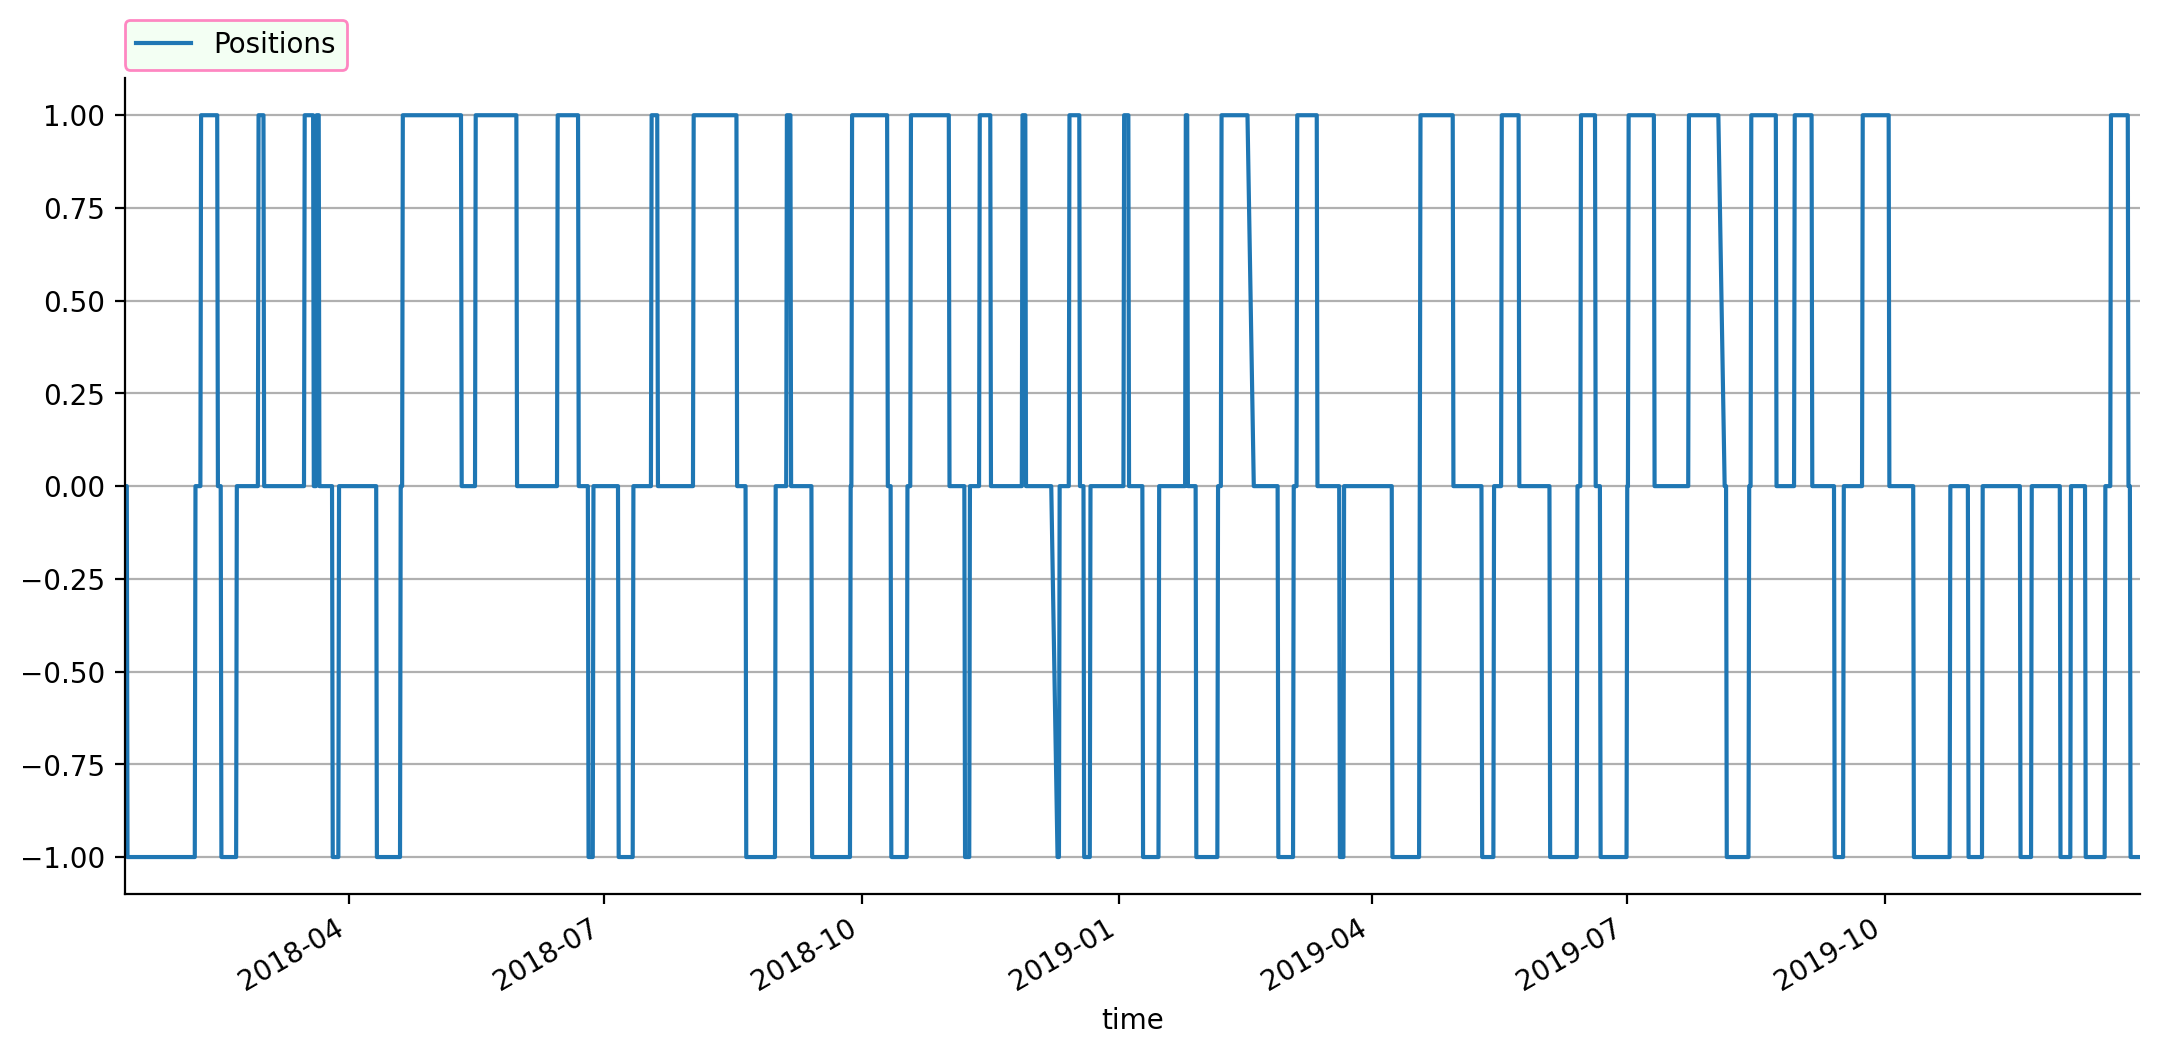

In [197]:
data.position.plot(figsize = (13,6), label = "Positions")
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
plt.grid(axis = "y")
plt.show()

## Vectorized Strategy Backtesting

In [198]:
data

,price,returns,SMA,Lower_Band,Upper_Band,distance,position
time,,,,,,,
2018-01-11 04:00:00+00:00,1.194770,-0.000498,1.200504,1.190849,1.210160,-0.005734,0.0
2018-01-11 10:00:00+00:00,1.204915,0.008455,1.200628,1.190841,1.210415,0.004287,0.0
2018-01-11 16:00:00+00:00,1.203205,-0.001420,1.200500,1.190964,1.210035,0.002705,0.0
2018-01-11 22:00:00+00:00,1.205165,0.001628,1.200524,1.190943,1.210104,0.004641,0.0
2018-01-12 04:00:00+00:00,1.212530,0.006093,1.200748,1.190374,1.211122,0.011782,-1.0
...,...,...,...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092,1.111391,1.105215,1.117567,0.008529,-1.0
2019-12-30 04:00:00+00:00,1.119940,0.000018,1.111553,1.104754,1.118352,0.008387,-1.0
2019-12-30 10:00:00+00:00,1.120095,0.000138,1.111777,1.104318,1.119235,0.008318,-1.0


In [199]:
data["strategy"] = data.position.shift(1) * data["returns"]

In [200]:
data.dropna(inplace = True)

In [201]:
data

,price,returns,SMA,Lower_Band,Upper_Band,distance,position,strategy
time,,,,,,,,
2018-01-11 10:00:00+00:00,1.204915,0.008455,1.200628,1.190841,1.210415,0.004287,0.0,0.000000
2018-01-11 16:00:00+00:00,1.203205,-0.001420,1.200500,1.190964,1.210035,0.002705,0.0,-0.000000
2018-01-11 22:00:00+00:00,1.205165,0.001628,1.200524,1.190943,1.210104,0.004641,0.0,0.000000
2018-01-12 04:00:00+00:00,1.212530,0.006093,1.200748,1.190374,1.211122,0.011782,-1.0,0.000000
2018-01-12 10:00:00+00:00,1.214820,0.001887,1.201086,1.189583,1.212589,0.013734,-1.0,-0.001887
...,...,...,...,...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092,1.111391,1.105215,1.117567,0.008529,-1.0,-0.002092
2019-12-30 04:00:00+00:00,1.119940,0.000018,1.111553,1.104754,1.118352,0.008387,-1.0,-0.000018
2019-12-30 10:00:00+00:00,1.120095,0.000138,1.111777,1.104318,1.119235,0.008318,-1.0,-0.000138


In [202]:
data["cum_returns"] = data["returns"].cumsum().apply(np.exp)
data["cum_strategy"] = data["strategy"].cumsum().apply(np.exp)

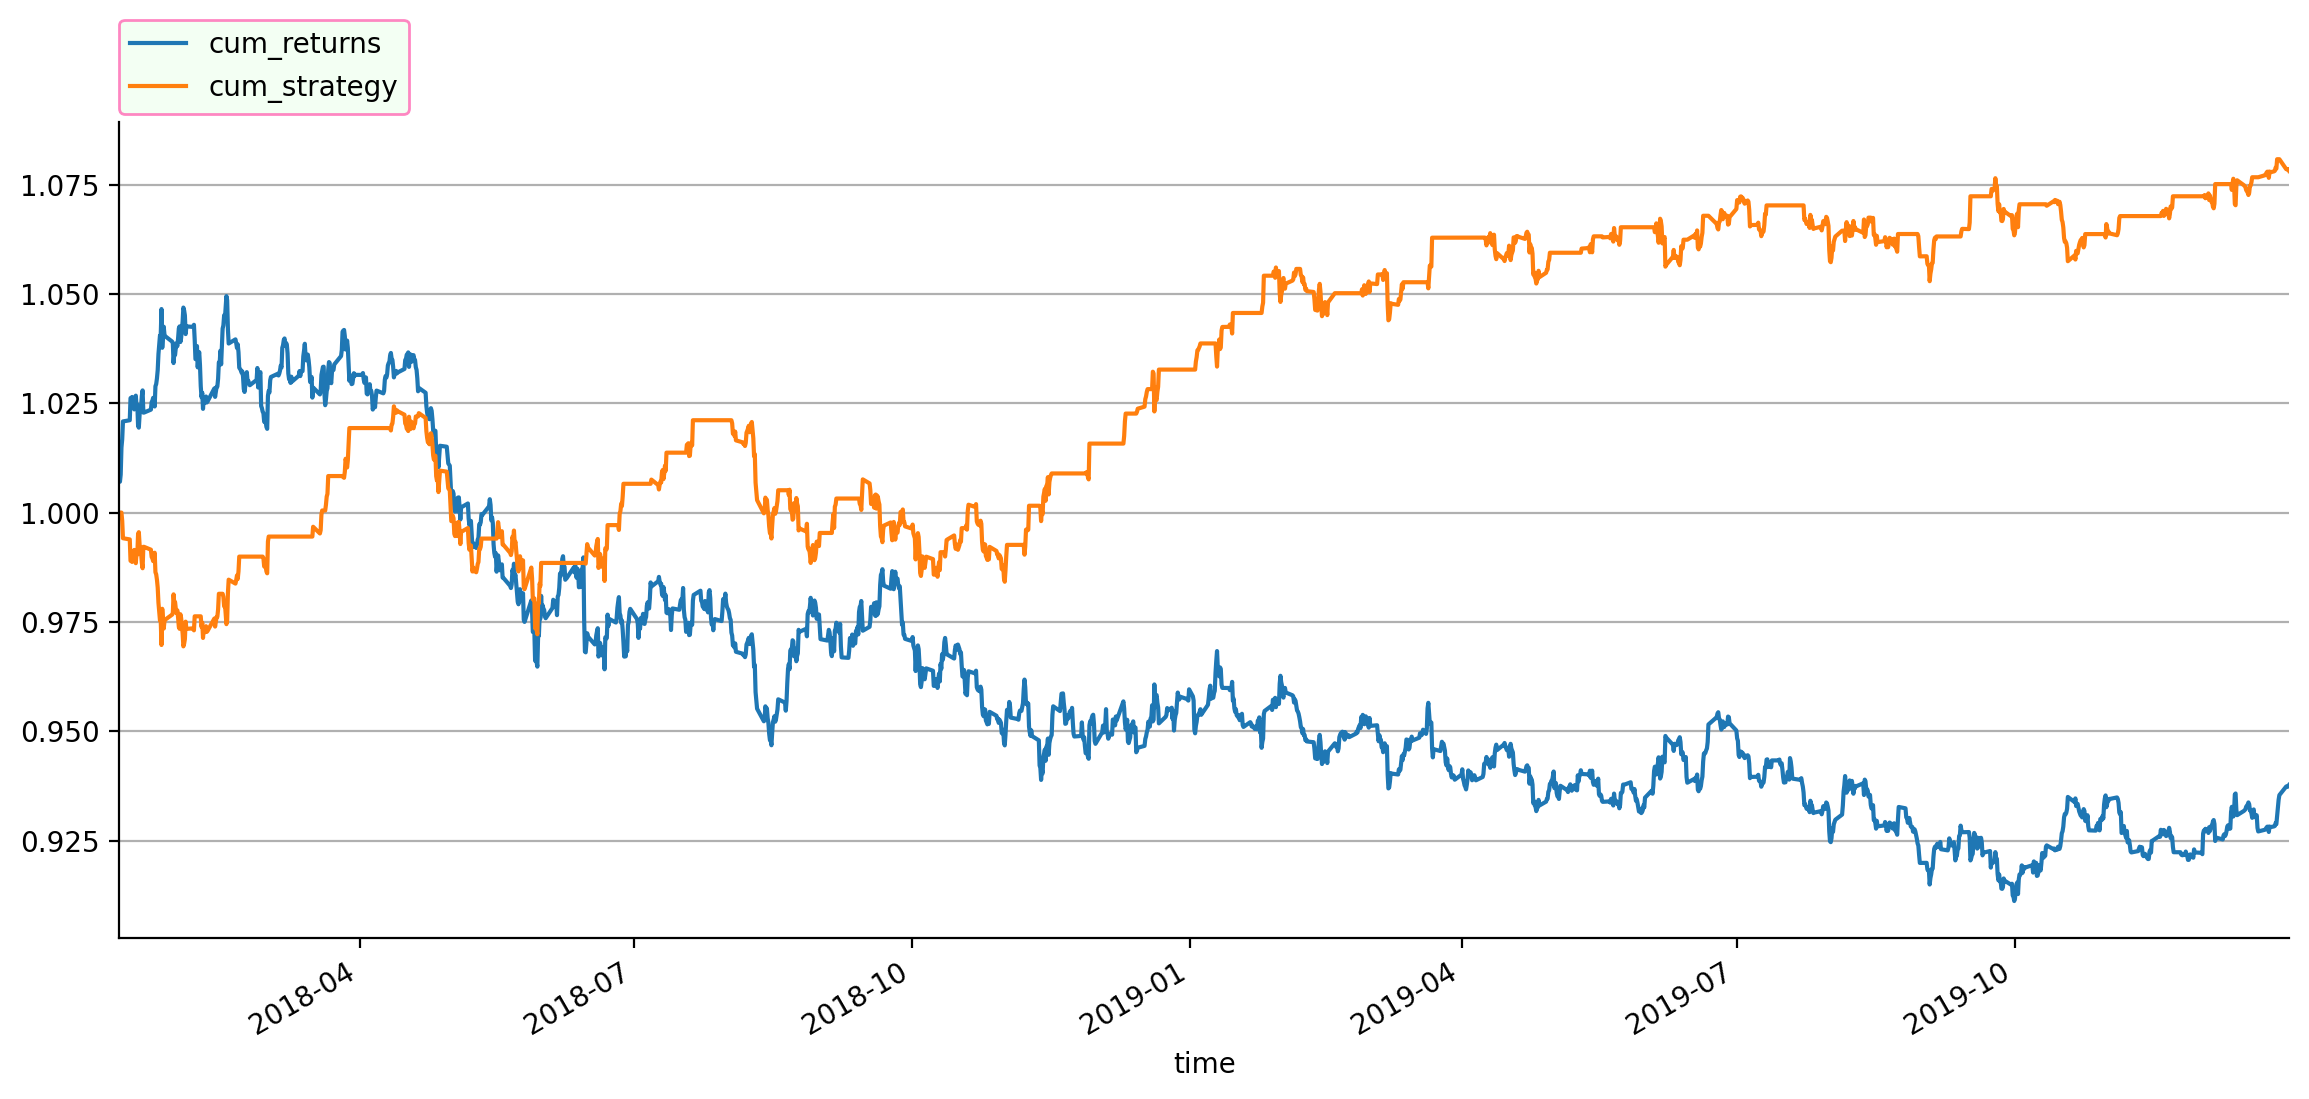

In [203]:
data[["cum_returns", "cum_strategy"]].plot(figsize = (14 , 6))
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
plt.grid(axis = "y")
plt.show()

In [204]:
data

,price,returns,SMA,Lower_Band,Upper_Band,distance,position,strategy,cum_returns,cum_strategy
time,,,,,,,,,,
2018-01-11 10:00:00+00:00,1.204915,0.008455,1.200628,1.190841,1.210415,0.004287,0.0,0.000000,1.008491,1.000000
2018-01-11 16:00:00+00:00,1.203205,-0.001420,1.200500,1.190964,1.210035,0.002705,0.0,-0.000000,1.007060,1.000000
2018-01-11 22:00:00+00:00,1.205165,0.001628,1.200524,1.190943,1.210104,0.004641,0.0,0.000000,1.008700,1.000000
2018-01-12 04:00:00+00:00,1.212530,0.006093,1.200748,1.190374,1.211122,0.011782,-1.0,0.000000,1.014865,1.000000
2018-01-12 10:00:00+00:00,1.214820,0.001887,1.201086,1.189583,1.212589,0.013734,-1.0,-0.001887,1.016781,0.998115
...,...,...,...,...,...,...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092,1.111391,1.105215,1.117567,0.008529,-1.0,-0.002092,0.937352,1.078555
2019-12-30 04:00:00+00:00,1.119940,0.000018,1.111553,1.104754,1.118352,0.008387,-1.0,-0.000018,0.937369,1.078536
2019-12-30 10:00:00+00:00,1.120095,0.000138,1.111777,1.104318,1.119235,0.008318,-1.0,-0.000138,0.937498,1.078387


In [205]:
ptc = 0.00007

In [206]:
data["trades"] = data.position.diff().fillna(0).abs()

In [207]:
data

,price,returns,SMA,Lower_Band,Upper_Band,distance,position,strategy,cum_returns,cum_strategy,trades
time,,,,,,,,,,,
2018-01-11 10:00:00+00:00,1.204915,0.008455,1.200628,1.190841,1.210415,0.004287,0.0,0.000000,1.008491,1.000000,0.0
2018-01-11 16:00:00+00:00,1.203205,-0.001420,1.200500,1.190964,1.210035,0.002705,0.0,-0.000000,1.007060,1.000000,0.0
2018-01-11 22:00:00+00:00,1.205165,0.001628,1.200524,1.190943,1.210104,0.004641,0.0,0.000000,1.008700,1.000000,0.0
2018-01-12 04:00:00+00:00,1.212530,0.006093,1.200748,1.190374,1.211122,0.011782,-1.0,0.000000,1.014865,1.000000,1.0
2018-01-12 10:00:00+00:00,1.214820,0.001887,1.201086,1.189583,1.212589,0.013734,-1.0,-0.001887,1.016781,0.998115,0.0
...,...,...,...,...,...,...,...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092,1.111391,1.105215,1.117567,0.008529,-1.0,-0.002092,0.937352,1.078555,0.0
2019-12-30 04:00:00+00:00,1.119940,0.000018,1.111553,1.104754,1.118352,0.008387,-1.0,-0.000018,0.937369,1.078536,0.0
2019-12-30 10:00:00+00:00,1.120095,0.000138,1.111777,1.104318,1.119235,0.008318,-1.0,-0.000138,0.937498,1.078387,0.0


In [208]:
data.trades.value_counts()

0.0    1929
1.0     111
Name: trades, dtype: int64

In [209]:
data["strategy_net"] = data.strategy - data.trades * (ptc)

In [210]:
data["cum_strategy_net"] = data.strategy_net.cumsum().apply(np.exp)

In [211]:
data

,price,returns,SMA,Lower_Band,Upper_Band,distance,position,strategy,cum_returns,cum_strategy,trades,strategy_net,cum_strategy_net
time,,,,,,,,,,,,,
2018-01-11 10:00:00+00:00,1.204915,0.008455,1.200628,1.190841,1.210415,0.004287,0.0,0.000000,1.008491,1.000000,0.0,0.000000,1.000000
2018-01-11 16:00:00+00:00,1.203205,-0.001420,1.200500,1.190964,1.210035,0.002705,0.0,-0.000000,1.007060,1.000000,0.0,-0.000000,1.000000
2018-01-11 22:00:00+00:00,1.205165,0.001628,1.200524,1.190943,1.210104,0.004641,0.0,0.000000,1.008700,1.000000,0.0,0.000000,1.000000
2018-01-12 04:00:00+00:00,1.212530,0.006093,1.200748,1.190374,1.211122,0.011782,-1.0,0.000000,1.014865,1.000000,1.0,-0.000070,0.999930
2018-01-12 10:00:00+00:00,1.214820,0.001887,1.201086,1.189583,1.212589,0.013734,-1.0,-0.001887,1.016781,0.998115,0.0,-0.001887,0.998045
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-12-29 22:00:00+00:00,1.119920,0.002092,1.111391,1.105215,1.117567,0.008529,-1.0,-0.002092,0.937352,1.078555,0.0,-0.002092,1.070207
2019-12-30 04:00:00+00:00,1.119940,0.000018,1.111553,1.104754,1.118352,0.008387,-1.0,-0.000018,0.937369,1.078536,0.0,-0.000018,1.070188
2019-12-30 10:00:00+00:00,1.120095,0.000138,1.111777,1.104318,1.119235,0.008318,-1.0,-0.000138,0.937498,1.078387,0.0,-0.000138,1.070040


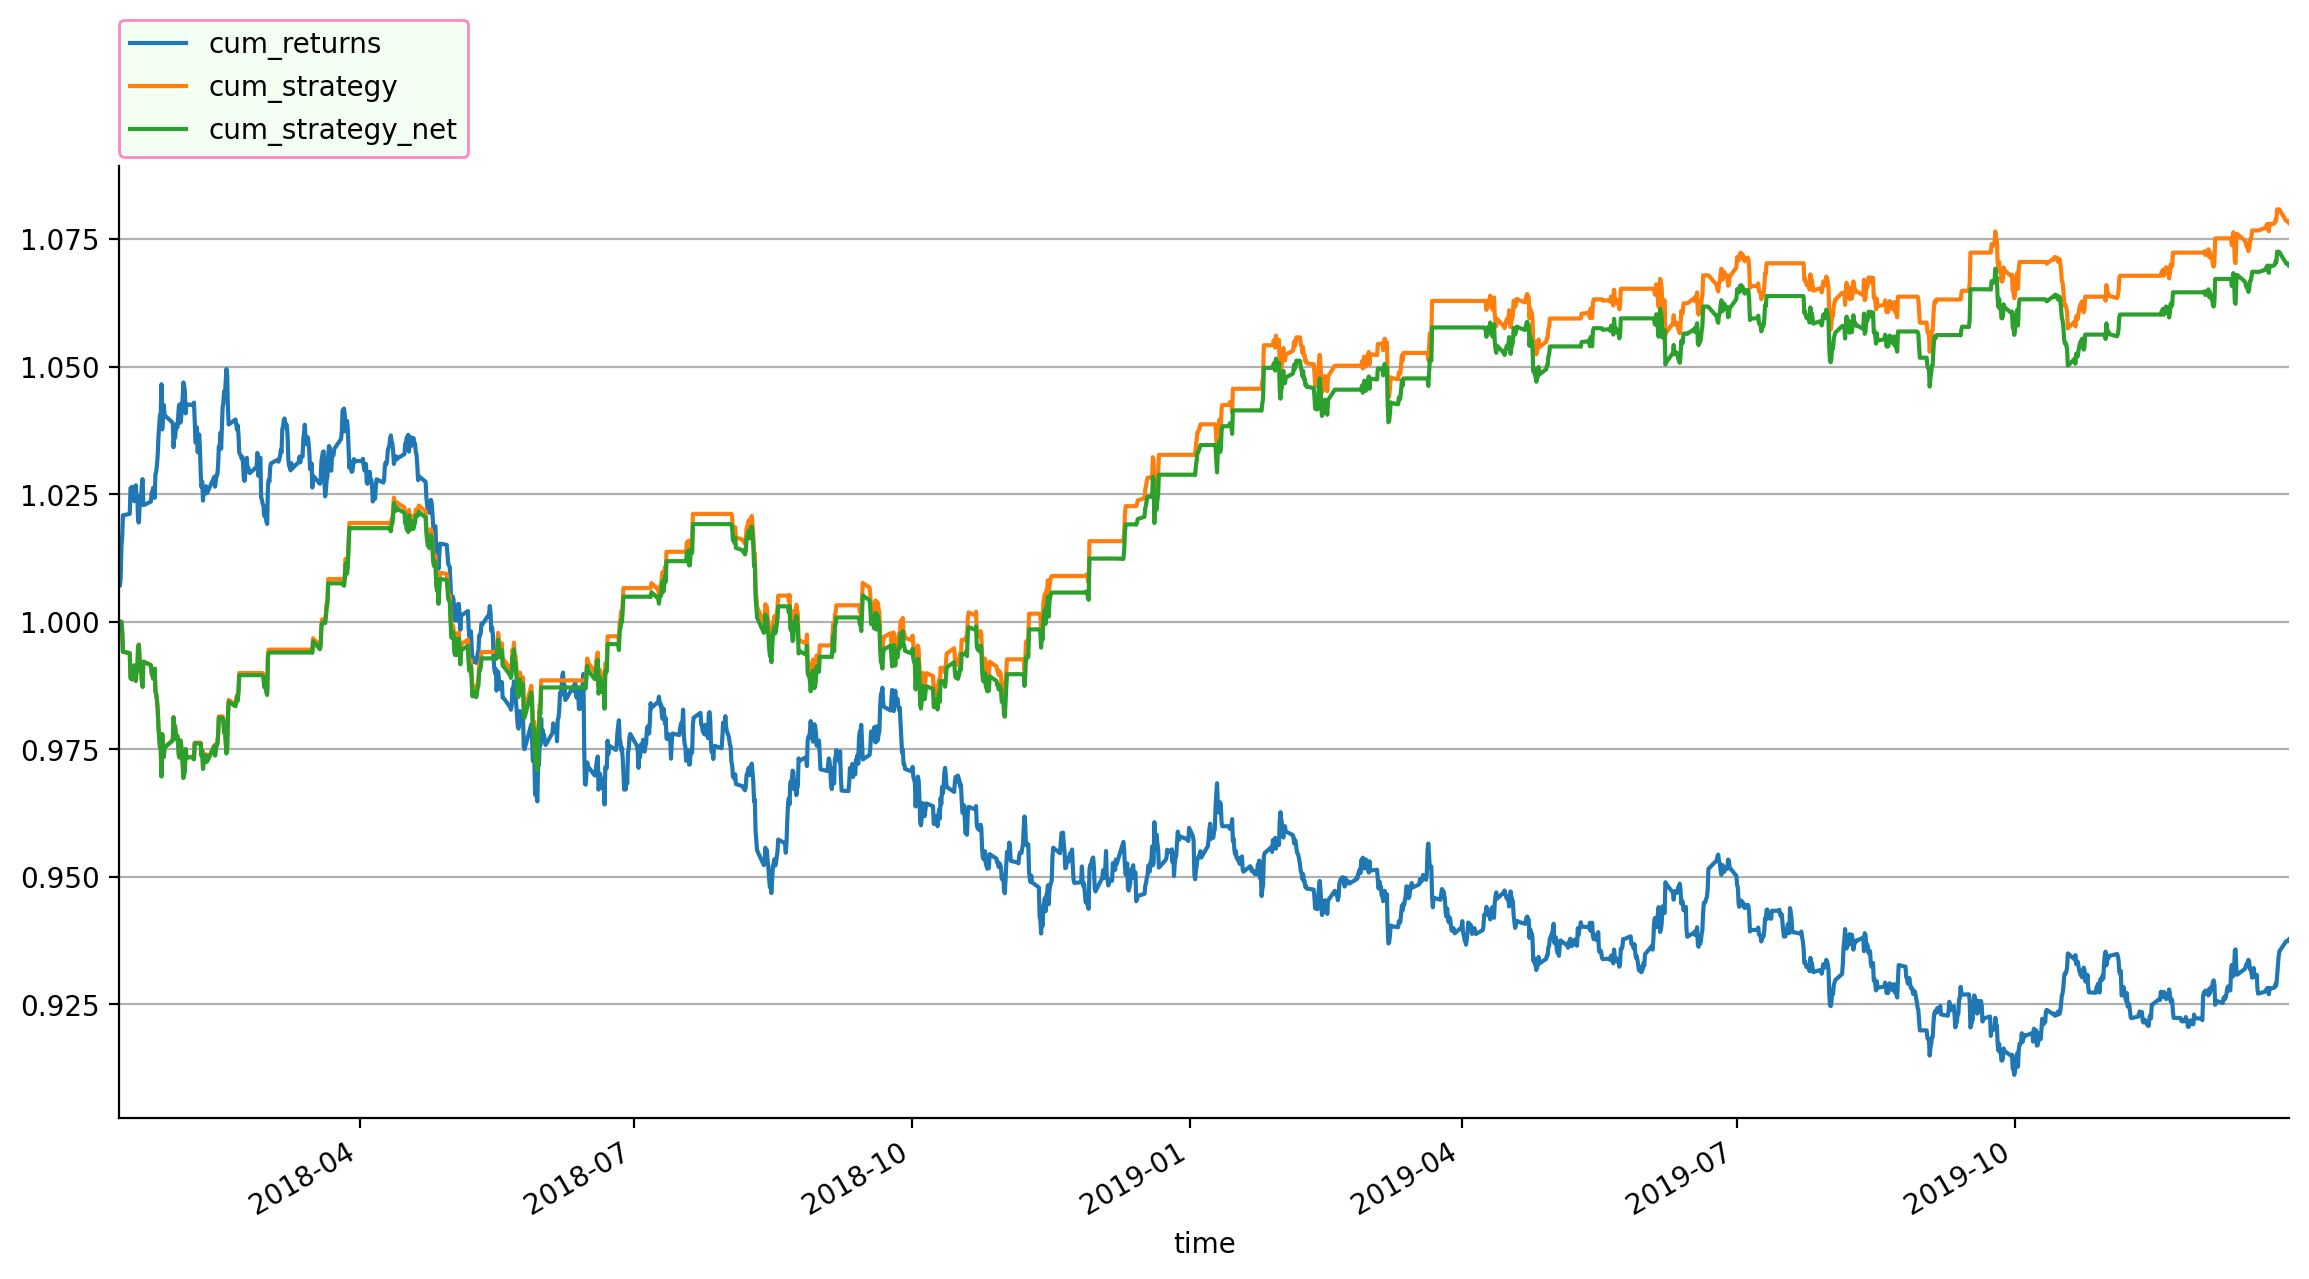

In [214]:
data[["cum_returns", "cum_strategy", "cum_strategy_net"]].plot(figsize = (14 , 7))
plt.gca().spines[["top" , "right"]].set_visible(False)
plt.autoscale(enable = True , axis ="x" , tight = True)
plt.legend(loc = (0,1.01) , fancybox = True,  frameon = True , facecolor = "honeydew" , edgecolor = "hotpink")
plt.grid(axis = "y")
plt.show()

In [215]:
data[["returns", "strategy_net"]].mean() * (4 * 252) # annualized return

returns        -0.031776
strategy_net    0.033335
dtype: float64

In [216]:
data[["returns", "strategy_net"]].std() * np.sqrt(4 * 252) # annualized risk

returns         0.059975
strategy_net    0.044624
dtype: float64

## Using the BBBacktester Class

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brute
plt.style.use("seaborn-v0_8")
from BBBacktester import BBBacktester as BB

In [ ]:
pd.read_csv("intraday_pairs.csv", parse_dates = ["time"], index_col = "time")

In [ ]:
ptc = 0.00007

In [ ]:
tester = BB("EURUSD", 30, 2, "2018-01-01", "2019-12-31", ptc)

In [ ]:
tester

In [ ]:
tester.test_strategy()

In [ ]:
tester.results

In [ ]:
tester.plot_results()

In [ ]:
tester.optimize_parameters((25, 100, 1), (1, 5, 1))

In [ ]:
tester.plot_results()

In [ ]:
tester.results

__GBPUSD__

In [ ]:
ptc = 0.00007

In [ ]:
tester = BB("GBPUSD", 30, 2, "2018-01-01", "2019-12-31", ptc)

In [ ]:
tester.test_strategy()

In [ ]:
tester.plot_results()

In [ ]:
tester.optimize_parameters((25, 100, 1), (1, 5, 1))

In [ ]:
tester.plot_results()